In [ ]:
import os
import re
import glob
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats, integrate, optimize

warnings.filterwarnings("ignore")

# all estimators below also have exact closed-form NumPy/SciPy implementations so this
# notebook runs deterministically in any Python 3.10+ environment with zero external dependencies)
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    HAS_STATSMODELS = True
except ImportError:
    HAS_STATSMODELS = False

sns.set_theme(style="ticks")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "font.family": "sans-serif",
    "axes.edgecolor": "#263238",
    "axes.linewidth": 1.1,
    "figure.autolayout": False,
})

def locate_data_directory():
    candidate_dirs = [
        ".",
        "./downloads",
        "./ucla_cnp_data",
        "/working_dir/c_6cafd8ae21bc991e/downloads",
        "/content",
        "/content/drive/MyDrive",
        "/content/drive/MyDrive/ISEF",
        "/content/drive/MyDrive/UCLA_CNP",
    ]
    # Attempt Colab Drive mount if running inside Google Colab and files not yet local
    for d in candidate_dirs:
        if os.path.exists(os.path.join(d, "ucla_cnp_behavioral_extracted.csv")):
            return d
    try:
        from google.colab import drive  # type: ignore
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive", force_remount=False)
        for root, _, files in os.walk("/content/drive/MyDrive"):
            if "ucla_cnp_behavioral_extracted.csv" in files:
                return root
    except Exception:
        pass
    raise FileNotFoundError(
        "Could not locate 'ucla_cnp_behavioral_extracted.csv'. Place the 6 project data tables "
        "(ucla_cnp_participants.csv, ucla_cnp_behavioral_extracted.csv, medication.tsv, bart.tsv, "
        "stopsignal.tsv, ucla_cnp_cross_task_env_extracted.csv) in your Colab working folder or MyDrive, "
        "or run rebuild_from_openneuro_s3() below to extract directly from OpenNeuro ds000030."
    )

def extract_bids_bart_sst_from_local_or_s3(bids_root="./cnp_task_data", sync_from_s3=False):
    """Extract BART cash-out pumps and Verbruggen et al. (2019) integration SSRT from BIDS TSVs."""
    if sync_from_s3:
        os.system(
            f'aws s3 sync --no-sign-request s3://openneuro.org/ds000030 "{bids_root}" '
            '--exclude "*" --include "participants.tsv" '
            '--include "*_task-bart_events.tsv" --include "*_task-stopsignal_events.tsv"'
        )
    bart_files = sorted(glob.glob(os.path.join(bids_root, "sub-*", "func", "*_task-bart_events.tsv")))
    sst_files = sorted(glob.glob(os.path.join(bids_root, "sub-*", "func", "*_task-stopsignal_events.tsv")))

    bart_rows = []
    for fpath in bart_files:
        sub_id = os.path.basename(fpath).split("_")[0]
        sub_df = pd.read_csv(fpath, sep="\t")
        # Verified unexploded cash-out pumps (fixes ISEF_Code Cell 2 len(df_trial)/30 bug)
        accept_df = sub_df[sub_df["action"] == "ACCEPT"]
        pumps_by_trial = accept_df.groupby("trial_number").size()
        unexploded_ids = sub_df[sub_df["explode_trial"] == 0]["trial_number"].unique()
        cashout_pumps = pumps_by_trial[pumps_by_trial.index.isin(unexploded_ids)]
        if len(cashout_pumps) > 0:
            bart_rows.append({
                "participant_id": sub_id,
                "BART_adj_pumps": float(cashout_pumps.mean()),
                "BART_cashout_balloons": int(len(cashout_pumps)),
                "BART_exploded_balloons": int(sub_df[sub_df["explode_trial"] == 1]["trial_number"].nunique()),
            })

    sst_rows = []
    for fpath in sst_files:
        sub_id = os.path.basename(fpath).split("_")[0]
        sub_df = pd.read_csv(fpath, sep="\t")
        go_df = sub_df[sub_df["trial_type"] == "GO"].copy()
        stop_df = sub_df[sub_df["trial_type"] == "STOP"].copy()
        if len(go_df) == 0 or len(stop_df) == 0:
            continue
        go_rt = pd.to_numeric(go_df["ReactionTime"], errors="coerce").fillna(0.0).values
        stop_rt = pd.to_numeric(stop_df["ReactionTime"], errors="coerce").fillna(0.0).values
        ssd = pd.to_numeric(stop_df["StopSignalDelay"], errors="coerce").dropna().values

        valid_go = go_rt > 0.100
        go_omission_rate = float(1.0 - np.mean(go_rt > 0))
        p_respond = float(np.mean(stop_rt > 0))
        mean_go_ms = float(np.mean(go_rt[valid_go]) * 1000.0)
        sd_go_ms = float(np.std(go_rt[valid_go], ddof=1) * 1000.0)
        mean_ssd_ms = float(np.mean(ssd) * 1000.0)
        failed_stop = stop_rt[stop_rt > 0.100]
        mean_fs_ms = float(np.mean(failed_stop) * 1000.0) if len(failed_stop) > 0 else np.nan

        # Verbruggen et al. (2019) Integration SSRT with omission replacement (max Go RT / 1.50 s)
        max_rt = max(float(np.max(go_rt[valid_go])), 1.50)
        go_replaced = np.where(go_rt > 0.100, go_rt, max_rt)
        sorted_go = np.sort(go_replaced)
        nth_idx = max(0, min(int(np.round(len(sorted_go) * p_respond)) - 1, len(sorted_go) - 1))
        ssrt_int_ms = float(sorted_go[nth_idx] * 1000.0 - mean_ssd_ms)

        sst_rows.append({
            "participant_id": sub_id,
            "SSRT_ms": ssrt_int_ms,
            "Mean_Go_RT_ms": mean_go_ms,
            "SD_Go_RT_ms": sd_go_ms,
            "Mean_SSD_ms": mean_ssd_ms,
            "Mean_Failed_Stop_RT_ms": mean_fs_ms,
            "P_respond_signal": p_respond,
            "Go_Omission_Rate": go_omission_rate,
            "n_valid_go": int(np.sum(valid_go)),
            "Violates_Independence": int(np.notna(mean_fs_ms) and mean_fs_ms > mean_go_ms),
            "Violates_P_Respond_Bounds": int((p_respond < 0.25) or (p_respond > 0.75)),
        })
    return pd.merge(pd.DataFrame(bart_rows), pd.DataFrame(sst_rows), on="participant_id", how="outer")

DATA_DIR = locate_data_directory()
FIG_OUT_DIR = "./figures_publication"
os.makedirs(FIG_OUT_DIR, exist_ok=True)
print(f"Environment initialized successfully | statsmodels available: {HAS_STATSMODELS}")
print(f"Resolved empirical dataset directory: {os.path.abspath(DATA_DIR)}")

Environment initialized successfully | statsmodels available: False
Resolved empirical dataset directory: /working_dir/c_6cafd8ae21bc991e/downloads


## 1. Load data, medication coding, EZ-diffusion, and SST QC

In [ ]:
part = pd.read_csv(os.path.join(DATA_DIR, "ucla_cnp_participants.csv"))
beh = pd.read_csv(os.path.join(DATA_DIR, "ucla_cnp_behavioral_extracted.csv"))
med = pd.read_csv(os.path.join(DATA_DIR, "medication.tsv"), sep="\t")
bart_desk = pd.read_csv(os.path.join(DATA_DIR, "bart.tsv"), sep="\t")
sst_desk = pd.read_csv(os.path.join(DATA_DIR, "stopsignal.tsv"), sep="\t")
cross_env = pd.read_csv(os.path.join(DATA_DIR, "ucla_cnp_cross_task_env_extracted.csv"))

df_all = (
    part.merge(beh, on="participant_id", how="left")
    .merge(med, on="participant_id", how="left")
    .merge(bart_desk, on="participant_id", how="left", suffixes=("", "_desk"))
    .merge(sst_desk, on="participant_id", how="left", suffixes=("", "_sstdesk"))
    .merge(cross_env, on="participant_id", how="left")
)
df_all["diagnosis"] = df_all["diagnosis"].astype(str).str.strip().str.upper()
df_all["gender"] = df_all["gender"].astype(str).str.strip().str.upper()

# Pharmacotherapy class coding across med_name1..med_name20
AP_DRUGS = [
    "olanzapine", "zyprexa", "risperidone", "risperdal", "quetiapine", "seroquel",
    "aripiprazole", "abilify", "clozapine", "clozaril", "ziprasidone", "geodon",
    "paliperidone", "invega", "haloperidol", "haldol", "fluphenazine", "prolixin",
    "perphenazine", "trilafon", "thiothixene", "navane", "trifluoperazine", "stelazine",
    "chlorpromazine", "thorazine", "lurasidone", "latuda", "asenapine", "saphris", "iloperidone"
]
STIM_DRUGS = [
    "methylphenidate", "ritalin", "concerta", "focalin", "dexmethylphenidate",
    "amphetamine", "adderall", "vyvanse", "lisdexamfetamine", "dextroamphetamine",
    "dexedrine", "modafinil", "provigil", "armodafinil", "nuvigil", "atomoxetine", "strattera"
]
MS_DRUGS = [
    "lithium", "valpro", "depakote", "divalproex", "lamotrigine",
    "lamictal", "carbamazepine", "tegretol", "oxcarbazepine", "trileptal"
]
AD_DRUGS = [
    "fluoxetine", "prozac", "sertraline", "zoloft", "escitalopram", "lexapro", "citalopram", "celexa",
    "paroxetine", "paxil", "venlafaxine", "effexor", "duloxetine", "cymbalta", "bupropion", "wellbutrin",
    "mirtazapine", "remeron", "trazodone", "amitriptyline", "nortriptyline", "desvenlafaxine", "pristiq"
]

def parse_medications(row):
    any_med, ap, stim, ms, ad = 0, 0, 0, 0, 0
    for i in range(1, 21):
        col = f"med_name{i}"
        if col in row and pd.notna(row[col]) and str(row[col]).strip().lower() not in ["", "nan", "none", "n/a"]:
            any_med = 1
            s = str(row[col]).lower()
            if any(k in s for k in AP_DRUGS): ap = 1
            if any(k in s for k in STIM_DRUGS): stim = 1
            if any(k in s for k in MS_DRUGS): ms = 1
            if any(k in s for k in AD_DRUGS): ad = 1
    return pd.Series([any_med, ap, stim, ms, ad], index=["any_med", "med_ap", "med_stim", "med_ms", "med_ad"])

df_all[["any_med", "med_ap", "med_stim", "med_ms", "med_ad"]] = df_all.apply(parse_medications, axis=1)

# Complete fMRI scanner BART + Stop-Signal cohort (N = 257)
df257 = df_all.dropna(subset=["BART_adj_pumps", "SSRT_ms", "Mean_Go_RT_ms", "Mean_SSD_ms", "age", "diagnosis"]).copy()
df257 = df257[df257["diagnosis"].isin(["CONTROL", "ADHD", "BIPOLAR", "SCHZ"])].reset_index(drop=True)

# Closed-form EZ-Diffusion decomposition (Wagenmakers et al., 2007, Psychonomic Bulletin & Review)
def fit_ez_diffusion(Pc, VRT_s2, MRT_s, N_trials, s=0.1):
    Pc_adj = np.where(Pc >= 1.0, 1.0 - 1.0 / (2.0 * np.maximum(N_trials, 10.0)), np.clip(Pc, 0.505, 1.0))
    L = np.log(Pc_adj / (1.0 - Pc_adj))
    x = L * (L * Pc_adj**2 - L * Pc_adj + Pc_adj - 0.5) / np.maximum(VRT_s2, 1e-8)
    v = np.sign(Pc_adj - 0.5) * s * (np.maximum(x, 1e-12) ** 0.25)
    a = (s**2 * L) / np.maximum(np.abs(v), 1e-8)
    y_exp = np.exp(np.clip(-v * a / s**2, -50.0, 50.0))
    MDT_s = (a / (2.0 * v)) * ((1.0 - y_exp) / (1.0 + y_exp))
    Ter_ms = (MRT_s - MDT_s) * 1000.0
    return v, a, Ter_ms

df257["EZ_v"], df257["EZ_a"], df257["EZ_Ter_ms"] = fit_ez_diffusion(
    1.0 - df257["Go_Omission_Rate"].values,
    (df257["SD_Go_RT_ms"].values / 1000.0) ** 2,
    df257["Mean_Go_RT_ms"].values / 1000.0,
    df257["n_valid_go"].values,
)
df257["ssrt_int_s"] = df257["SSRT_ms"] / 1000.0
df257["ssrt_mean_ms"] = df257["Mean_Go_RT_ms"] - df257["Mean_SSD_ms"]
df257["ssrt_mean_s"] = df257["ssrt_mean_ms"] / 1000.0
df257["go_rt_s"] = df257["Mean_Go_RT_ms"] / 1000.0
df257["ADHD"] = (df257["diagnosis"] == "ADHD").astype(float)
df257["BIPOLAR"] = (df257["diagnosis"] == "BIPOLAR").astype(float)
df257["SCHZ"] = (df257["diagnosis"] == "SCHZ").astype(float)
df257["female"] = (df257["gender"] == "F").astype(float)

# Verbruggen et al. (2019) Consensus Race-Model Quality Control Filter (N = 257 -> N = 234)
v_ind = df257["Violates_Independence"] == 1
v_bnd = df257["Violates_P_Respond_Bounds"] == 1
v_omi = df257["Go_Omission_Rate"] > 0.15
qc_mask = (~v_ind) & (~v_bnd) & (~v_omi)
df = df257[qc_mask].copy().reset_index(drop=True)
N = len(df)

print(" VERBRUGGEN ET AL. (2019) CONSENSUS QUALITY CONTROL AUDIT ".strip())
print(f"Complete scanner BART + Stop-Signal sample: N = {len(df257)} "
      f"({dict(df257['diagnosis'].value_counts())})")
print(f"  [1] Context/race independence violations (Mean Failed-Stop RT > Mean Go RT): n = {int(v_ind.sum())}")
print(f"  [2] Staircase tracking bound violations (P[respond|signal] outside [0.25, 0.75]): n = {int(v_bnd.sum())}")
print(f"  [3] Excessive Go trial omissions (> 15%): n = {int(v_omi.sum())}")
print(f"  --> Total unique excluded participants: n = {int((~qc_mask).sum())} | Primary Retained Cohort: N = {N}")
print(f"  --> Retained cohort breakdown: {dict(df['diagnosis'].value_counts())}")
print(f"  --> Retained P(respond|signal): M = {df['P_respond_signal'].mean():.3f}, SD = {df['P_respond_signal'].std():.3f} "
      f"(range {df['P_respond_signal'].min():.3f}-{df['P_respond_signal'].max():.3f})")
print(f"  --> Retained Go omission rate: M = {df['Go_Omission_Rate'].mean()*100:.2f}% (max {df['Go_Omission_Rate'].max()*100:.1f}%)")
print(f"  --> Retained BART cash-out balloons: M = {df['BART_cashout_balloons'].mean():.1f}, SD = {df['BART_cashout_balloons'].std():.1f}")

clin234 = df[df["diagnosis"] != "CONTROL"]
print(f"  --> Clinical pharmacotherapy (n = {len(clin234)}): {int(clin234['any_med'].sum())} medicated, "
      f"{len(clin234) - int(clin234['any_med'].sum())} unmedicated "
      f"(Antipsychotics n={int(clin234['med_ap'].sum())}, Mood Stabilizers n={int(clin234['med_ms'].sum())}, "
      f"Antidepressants n={int(clin234['med_ad'].sum())}, Psychostimulants n={int(clin234['med_stim'].sum())})")

VERBRUGGEN ET AL. (2019) CONSENSUS QUALITY CONTROL AUDIT
Complete scanner BART + Stop-Signal sample: N = 257 ({'CONTROL': np.int64(120), 'SCHZ': np.int64(49), 'BIPOLAR': np.int64(48), 'ADHD': np.int64(40)})
  [1] Context/race independence violations (Mean Failed-Stop RT > Mean Go RT): n = 13
  [2] Staircase tracking bound violations (P[respond|signal] outside [0.25, 0.75]): n = 6
  [3] Excessive Go trial omissions (> 15%): n = 6
  --> Total unique excluded participants: n = 23 | Primary Retained Cohort: N = 234
  --> Retained cohort breakdown: {'CONTROL': np.int64(117), 'SCHZ': np.int64(44), 'BIPOLAR': np.int64(42), 'ADHD': np.int64(31)}
  --> Retained P(respond|signal): M = 0.511, SD = 0.074 (range 0.312-0.719)
  --> Retained Go omission rate: M = 0.75% (max 10.4%)
  --> Retained BART cash-out balloons: M = 11.4, SD = 3.4
  --> Clinical pharmacotherapy (n = 117): 85 medicated, 32 unmedicated (Antipsychotics n=60, Mood Stabilizers n=32, Antidepressants n=35, Psychostimulants n=14)


## 2. SSRT convergence and sensitivity power

In [ ]:
r_conv, p_conv = stats.pearsonr(df["ssrt_mean_ms"], df["SSRT_ms"])
t_conv = r_conv * np.sqrt((N - 2) / (1.0 - r_conv**2))
print("DUAL-ESTIMATOR SSRT CONSTRUCT CONVERGENCE (N = 234) ")
print(f"Integration SSRT vs. Consensus Mean SSRT: r = {r_conv:.4f}, t({N-2}) = {t_conv:.2f}, p = {p_conv:.4e}")

def compute_sesoi_f2(df1, df2, n_total, power=0.80, alpha=0.05):
    f_crit = stats.f.ppf(1.0 - alpha, df1, df2)
    ncp = optimize.brentq(lambda lam: stats.ncf.sf(f_crit, df1, df2, lam) - power, 1e-6, 250.0)
    f2 = ncp / n_total
    rp2 = f2 / (1.0 + f2)
    return f2, rp2, np.sqrt(rp2)

print("\nSENSITIVITY POWER ANALYSIS / SESOI (N = 234, alpha = .05 two-tailed) ")
power_rows = []
for label, df1, df2 in [
    ("Model 3 Single Predictor (df = 1, 227)", 1, 227),
    ("Model 4 Single Predictor (df = 1, 224)", 1, 224),
    ("Omnibus 9-Predictor Model 4 (df = 9, 224)", 9, 224),
    ("Four-Group One-Way ANOVA (df = 3, 230)", 3, 230),
]:
    f80, r80, rp80 = compute_sesoi_f2(df1, df2, N, power=0.80)
    f50, r50, rp50 = compute_sesoi_f2(df1, df2, N, power=0.50)
    power_rows.append({
        "Test Specification": label,
        "80% Power f²": f"{f80:.4f}",
        "80% Partial R² / ηp²": f"{r80*100:.2f}%",
        "80% |rp| / f": f"|rp|={rp80:.3f} (f={np.sqrt(f80):.3f})",
        "50% Power f² (R²)": f"{f50:.4f} ({r50*100:.2f}%)",
    })
print(pd.DataFrame(power_rows).to_string(index=False))

DUAL-ESTIMATOR SSRT CONSTRUCT CONVERGENCE (N = 234) 
Integration SSRT vs. Consensus Mean SSRT: r = 0.9099, t(232) = 33.41, p = 1.2568e-90

SENSITIVITY POWER ANALYSIS / SESOI (N = 234, alpha = .05 two-tailed) 
                       Test Specification 80% Power f² 80% Partial R² / ηp²         80% |rp| / f 50% Power f² (R²)
   Model 3 Single Predictor (df = 1, 227)       0.0338                3.27% |rp|=0.181 (f=0.184)    0.0166 (1.63%)
   Model 4 Single Predictor (df = 1, 224)       0.0338                3.27% |rp|=0.181 (f=0.184)    0.0166 (1.63%)
Omnibus 9-Predictor Model 4 (df = 9, 224)       0.0694                6.49% |rp|=0.255 (f=0.263)    0.0391 (3.76%)
   Four-Group One-Way ANOVA (df = 3, 230)       0.0474                4.52% |rp|=0.213 (f=0.218)    0.0250 (2.44%)


## 3. Cohort descriptives and group comparisons (Table 1)

In [ ]:
def ols_complete(y_vec, X_mat, names):
    n, k = X_mat.shape
    b = np.linalg.lstsq(X_mat, y_vec, rcond=None)[0]
    res = y_vec - X_mat @ b
    rss = float(np.sum(res**2))
    tss = float(np.sum((y_vec - y_vec.mean()) ** 2))
    r2 = 1.0 - rss / tss
    adj = 1.0 - (1.0 - r2) * (n - 1) / (n - k)
    s2 = rss / (n - k)
    xtx_inv = np.linalg.inv(X_mat.T @ X_mat)
    cov = s2 * xtx_inv
    se = np.sqrt(np.diag(cov))
    t_vals = b / se
    p_vals = 2.0 * stats.t.sf(np.abs(t_vals), df=n - k)
    ci_half = stats.t.ppf(0.975, df=n - k) * se
    sd_x = np.std(X_mat, axis=0, ddof=1)
    sd_y = np.std(y_vec, ddof=1)
    sb = np.where(sd_x > 0, b * sd_x / sd_y, 0.0)
    sr2 = (t_vals**2 * (1.0 - r2)) / (n - k)
    ll = -0.5 * n * (np.log(2.0 * np.pi) + np.log(rss / n) + 1.0)
    bic = -2.0 * ll + k * np.log(n)
    f_val = ((tss - rss) / (k - 1)) / s2 if k > 1 else np.nan
    f_p = float(stats.f.sf(f_val, k - 1, n - k)) if k > 1 else np.nan
    H_diag = np.einsum("ij,jk,ik->i", X_mat, xtx_inv, X_mat)
    cooks_d = (res**2 / (k * s2)) * (H_diag / ((1.0 - H_diag) ** 2))
    return dict(
        n=n, k=k, df_r=n - k, names=names, b=b, se=se, t=t_vals, p=p_vals,
        lo=b - ci_half, hi=b + ci_half, sb=sb, sr2=sr2, rss=rss, tss=tss,
        r2=r2, adj=adj, bic=bic, f=f_val, fp=f_p, res=res, cooks_d=cooks_d,
    )

COHORT_ORDER = ["CONTROL", "ADHD", "BIPOLAR", "SCHZ"]
COHORT_TITLES = {
    "CONTROL": "Healthy Controls",
    "ADHD": "ADHD",
    "BIPOLAR": "Bipolar I Disorder",
    "SCHZ": "Schizophrenia",
}

t1_rows = []
for g in COHORT_ORDER:
    sub = df[df["diagnosis"] == g]
    q25, q50, q75 = np.percentile(sub["BART_adj_pumps"], [25, 50, 75])
    t1_rows.append({
        "Cohort": f"{COHORT_TITLES[g]} (n = {len(sub)})",
        "Age M (SD)": f"{sub['age'].mean():.1f} ({sub['age'].std(ddof=1):.1f})",
        "Female (%)": f"{sub['female'].mean()*100:.1f}%",
        "BART Pumps M (SD)": f"{sub['BART_adj_pumps'].mean():.3f} ({sub['BART_adj_pumps'].std(ddof=1):.3f})",
        "BART Mdn [IQR]": f"{q50:.3f} [{q25:.3f}, {q75:.3f}]",
        "Integration SSRT ms": f"{sub['SSRT_ms'].mean():.1f} ({sub['SSRT_ms'].std(ddof=1):.1f})",
        "Mean SSRT ms": f"{sub['ssrt_mean_ms'].mean():.1f} ({sub['ssrt_mean_ms'].std(ddof=1):.1f})",
        "Mean Go RT ms": f"{sub['Mean_Go_RT_ms'].mean():.1f} ({sub['Mean_Go_RT_ms'].std(ddof=1):.1f})",
        "EZ Boundary a": f"{sub['EZ_a'].mean():.3f} ({sub['EZ_a'].std(ddof=1):.3f})",
    })
df_table1 = pd.DataFrame(t1_rows)
print("MANUSCRIPT TABLE 1: COHORT DEMOGRAPHICS & NEUROCOGNITIVE TASK DESCRIPTIVES (N = 234) ")
print(df_table1.to_string(index=False))

y = df["BART_adj_pumps"].values
m_null = ols_complete(y, np.ones((N, 1)), ["Intercept"])
m0 = ols_complete(y, np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"]]),
                  ["Intercept", "ADHD", "BIPOLAR", "SCHZ"])
omega2 = (m0["tss"] - m0["rss"] - 3.0 * (m0["rss"] / m0["df_r"])) / (m0["tss"] + m0["rss"] / m0["df_r"])

print(f"\nCATEGORICAL DIAGNOSTIC CONTRASTS ON BART ADJUSTED PUMPS (N = 234) ")
print(f"Omnibus One-Way ANOVA: F(3, {m0['df_r']}) = {m0['f']:.3f}, p = {m0['fp']:.4f}, "
      f"eta_p^2 = {m0['r2']:.4f}, omega^2 = {omega2:.4f}")
print(f"BIC(intercept-only null) = {m_null['bic']:.2f} vs. BIC(Model 0 categorical) = {m0['bic']:.2f}")

def jzs_two_sample_bf10(t_eq, n1, n2, r_scale=0.7071):
    n_eff = (n1 * n2) / (n1 + n2)
    df_eq = n1 + n2 - 2
    def integrand(g):
        prior = (r_scale / np.sqrt(2.0 * np.pi)) * (g ** -1.5) * np.exp(-(r_scale**2) / (2.0 * g))
        like = ((1.0 + n_eff * g) ** -0.5) * (
            ((1.0 + (t_eq**2) / (df_eq * (1.0 + n_eff * g))) ** (-(df_eq + 1.0) / 2.0))
            / ((1.0 + (t_eq**2) / df_eq) ** (-(df_eq + 1.0) / 2.0))
        )
        return prior * like
    return float(integrate.quad(integrand, 0.0, np.inf, limit=250)[0])

ctrl_vals = df.loc[df["diagnosis"] == "CONTROL", "BART_adj_pumps"].values
for g in ["SCHZ", "BIPOLAR", "ADHD"]:
    g_vals = df.loc[df["diagnosis"] == g, "BART_adj_pumps"].values
    t_w, p_w = stats.ttest_ind(g_vals, ctrl_vals, equal_var=False)
    v1 = np.var(g_vals, ddof=1) / len(g_vals)
    v2 = np.var(ctrl_vals, ddof=1) / len(ctrl_vals)
    df_w = (v1 + v2) ** 2 / ((v1**2) / (len(g_vals) - 1) + (v2**2) / (len(ctrl_vals) - 1))
    s_pool = np.sqrt(((len(g_vals) - 1) * np.var(g_vals, ddof=1) + (len(ctrl_vals) - 1) * np.var(ctrl_vals, ddof=1))
                     / (len(g_vals) + len(ctrl_vals) - 2))
    d_val = (g_vals.mean() - ctrl_vals.mean()) / s_pool
    se_d = np.sqrt(1.0 / len(g_vals) + 1.0 / len(ctrl_vals) + (d_val**2) / (2.0 * (len(g_vals) + len(ctrl_vals))))
    t_eq, _ = stats.ttest_ind(g_vals, ctrl_vals, equal_var=True)
    bf10 = jzs_two_sample_bf10(t_eq, len(g_vals), len(ctrl_vals), r_scale=0.7071)
    print(f"  {g:8s} vs. CONTROL: Welch t({df_w:.2f}) = {t_w:.3f}, p = {p_w:.4f}, "
          f"d = {d_val:.3f} [95% CI {d_val - 1.96*se_d:.3f}, {d_val + 1.96*se_d:.3f}], "
          f"JZS BF10 = {bf10:.2f} (BF01 = {1.0/bf10:.2f})")

MANUSCRIPT TABLE 1: COHORT DEMOGRAPHICS & NEUROCOGNITIVE TASK DESCRIPTIVES (N = 234) 
                     Cohort  Age M (SD) Female (%) BART Pumps M (SD)       BART Mdn [IQR] Integration SSRT ms Mean SSRT ms Mean Go RT ms EZ Boundary a
 Healthy Controls (n = 117)  31.5 (8.9)      47.0%     4.334 (1.284) 4.300 [3.333, 5.067]        219.2 (59.3) 229.4 (56.0) 488.3 (103.4) 0.128 (0.018)
              ADHD (n = 31) 32.4 (10.1)      48.4%     4.398 (1.647) 4.000 [3.182, 5.100]        220.4 (62.9) 231.1 (56.8) 511.0 (129.3) 0.127 (0.020)
Bipolar I Disorder (n = 42)  34.9 (8.9)      47.6%     4.356 (1.415) 4.191 [3.199, 5.192]        229.1 (69.9) 233.5 (63.2)  530.2 (94.3) 0.136 (0.020)
     Schizophrenia (n = 44)  36.3 (9.2)      27.3%     3.614 (1.108) 3.563 [2.782, 4.628]        258.0 (78.0) 272.2 (70.6) 577.3 (128.0) 0.146 (0.020)

CATEGORICAL DIAGNOSTIC CONTRASTS ON BART ADJUSTED PUMPS (N = 234) 
Omnibus One-Way ANOVA: F(3, 230) = 3.658, p = 0.0132, eta_p^2 = 0.0455, omega^2 = 0.0330
BI

## 4. Hierarchical regressions, Bayes factors, and TOST (Table 2)

In [ ]:
m1 = ols_complete(
    y,
    np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"]]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age"],
)
m2 = ols_complete(
    y,
    np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"]]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "go_rt_s"],
)
m3 = ols_complete(
    y,
    np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"], df["ssrt_int_s"]]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "go_rt_s", "ssrt_int_s"],
)
m4 = ols_complete(
    y,
    np.column_stack([
        np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"], df["ssrt_int_s"],
        df["ssrt_int_s"] * df["ADHD"], df["ssrt_int_s"] * df["BIPOLAR"], df["ssrt_int_s"] * df["SCHZ"],
    ]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "go_rt_s", "ssrt_int_s",
     "SSRTxADHD", "SSRTxBIPOLAR", "SSRTxSCHZ"],
)

def nested_f_change(m_red, m_full):
    df1 = m_full["k"] - m_red["k"]
    df2 = m_full["df_r"]
    f_chg = ((m_red["rss"] - m_full["rss"]) / df1) / (m_full["rss"] / df2)
    p_chg = float(stats.f.sf(f_chg, df1, df2))
    return (m_full["r2"] - m_red["r2"]) * 100.0, f_chg, df1, df2, p_chg

def fmt_coef(model, var_name):
    if var_name not in model["names"]:
        return "—"
    idx = model["names"].index(var_name)
    pv = model["p"][idx]
    stars = "***" if pv < 0.001 else ("**" if pv < 0.01 else ("*" if pv < 0.05 else ""))
    return f"{model['b'][idx]:.3f} ({model['se'][idx]:.3f}){stars}"

all_vars = ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "go_rt_s", "ssrt_int_s",
            "SSRTxADHD", "SSRTxBIPOLAR", "SSRTxSCHZ"]
var_labels = {
    "Intercept": "Intercept",
    "ADHD": "ADHD (vs. Control)",
    "BIPOLAR": "Bipolar I (vs. Control)",
    "SCHZ": "Schizophrenia (vs. Control)",
    "age": "Age (years)",
    "go_rt_s": "Mean Go RT (s)",
    "ssrt_int_s": "Integration SSRT (s)",
    "SSRTxADHD": "SSRT × ADHD",
    "SSRTxBIPOLAR": "SSRT × Bipolar I",
    "SSRTxSCHZ": "SSRT × Schizophrenia",
}

t2_records = []
for v in all_vars:
    bsr = "—"
    if v in m3["names"] and v != "Intercept":
        idx3 = m3["names"].index(v)
        bsr = f"{m3['sb'][idx3]:.3f} / {m3['sr2'][idx3]:.4f}"
    t2_records.append({
        "Regressor": var_labels[v],
        "Model 0 (Diag)": fmt_coef(m0, v),
        "Model 1 (+Age)": fmt_coef(m1, v),
        "Model 2 (+Go RT)": fmt_coef(m2, v),
        "Model 3 (Additive)": fmt_coef(m3, v),
        "Model 3 (β / sr²)": bsr,
        "Model 4 (Moderation)": fmt_coef(m4, v),
    })

dr1, f1, _, _, p1 = nested_f_change(m0, m1)
dr2, f2, _, _, p2 = nested_f_change(m1, m2)
dr3, f3, _, _, p3 = nested_f_change(m2, m3)
dr4, f4, _, _, p4 = nested_f_change(m3, m4)

print("MANUSCRIPT TABLE 2: HIERARCHICAL OLS MODELS PREDICTING BART ADJUSTED PUMPS (N = 234) ")
print(pd.DataFrame(t2_records).to_string(index=False))
print("\n--- Model Fit & Nested Comparisons ---")
print(f"Model 0 (Diagnosis):   R² = {m0['r2']*100:.2f}%, R²_adj = {m0['adj']*100:.2f}%, F(3, 230) = {m0['f']:.3f}, p = {m0['fp']:.4f}, BIC = {m0['bic']:.2f}")
print(f"Model 1 (+Age):        R² = {m1['r2']*100:.2f}%, R²_adj = {m1['adj']*100:.2f}%, ΔR² = +{dr1:.2f}%, ΔF(1, 229) = {f1:.3f}, p = {p1:.4f}, BIC = {m1['bic']:.2f}")
print(f"Model 2 (+Mean Go RT): R² = {m2['r2']*100:.2f}%, R²_adj = {m2['adj']*100:.2f}%, ΔR² = +{dr2:.2f}%, ΔF(1, 228) = {f2:.3f}, p = {p2:.4f}, BIC = {m2['bic']:.2f}")
print(f"Model 3 (+SSRT_int):   R² = {m3['r2']*100:.2f}%, R²_adj = {m3['adj']*100:.2f}%, ΔR² = +{dr3:.2f}%, ΔF(1, 227) = {f3:.3f}, p = {p3:.4f}, BIC = {m3['bic']:.2f} (Omnibus F(6, 227) = {m3['f']:.3f}, p = {m3['fp']:.4f})")
print(f"Model 4 (Moderation):  R² = {m4['r2']*100:.2f}%, R²_adj = {m4['adj']*100:.2f}%, ΔR² = +{dr4:.2f}%, ΔF(3, 224) = {f4:.3f}, p = {p4:.4f}, BIC = {m4['bic']:.2f}")

print("\n--- Exact Model 3 Parameter Confidence Intervals ---")
for i, nm in enumerate(m3["names"]):
    print(f"  {nm:12s}: b = {m3['b'][i]:+8.4f}, SE = {m3['se'][i]:.4f}, t(227) = {m3['t'][i]:+7.3f}, "
          f"p = {m3['p'][i]:.4f}, 95% CI [{m3['lo'][i]:+7.3f}, {m3['hi'][i]:+7.3f}], β = {m3['sb'][i]:+.3f}, sr² = {m3['sr2'][i]:.4f}")

# Biological sex covariate check & VIFs
m3_sex = ols_complete(
    y,
    np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["female"], df["go_rt_s"], df["ssrt_int_s"]]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "female", "go_rt_s", "ssrt_int_s"],
)
print(f"\nBiological sex in Model 3: female b = {m3_sex['b'][5]:.3f}, SE = {m3_sex['se'][5]:.3f}, t = {m3_sex['t'][5]:.3f}, p = {m3_sex['p'][5]:.4f}")

X_vif = np.column_stack([df["ssrt_int_s"], df["go_rt_s"], df["age"], df["ADHD"], df["BIPOLAR"], df["SCHZ"]])
vif_names = ["SSRT_int", "Mean_Go_RT", "Age", "ADHD", "BIPOLAR", "SCHZ"]
vifs = {}
for idx_v, vn in enumerate(vif_names):
    xi = X_vif[:, idx_v]
    xo = np.column_stack([np.ones(N), np.delete(X_vif, idx_v, axis=1)])
    r2_i = ols_complete(xi, xo, ["c"] * 6)["r2"]
    vifs[vn] = 1.0 / (1.0 - r2_i)
print("Model 3 Variance Inflation Factors (VIF):", {k: round(v, 3) for k, v in vifs.items()})

# Exact Liang-Rouder-Morey (2012) Nested JZS Bayes Factor & Lakens (2017) TOST Equivalence for SSRT
delta_bic_ssrt = m3["bic"] - m2["bic"]
bic_bf01_ssrt = float(np.exp(delta_bic_ssrt / 2.0))

def jzs_nested_regression_bf01(r2_reduced, k_reduced, r2_full, k_full, n_obs, r_scale=0.7071):
    def marg_bf_vs_intercept(r2_val, k_pred):
        def integrand(g):
            log_p = np.log(r_scale / np.sqrt(2.0 * np.pi)) - 1.5 * np.log(g) - (r_scale**2) / (2.0 * g)
            log_b = 0.5 * (n_obs - k_pred - 1.0) * np.log(1.0 + n_obs * g) - 0.5 * (n_obs - 1.0) * np.log(1.0 + n_obs * g * (1.0 - r2_val))
            return np.exp(log_p + log_b)
        return float(integrate.quad(integrand, 1e-10, np.inf, limit=250)[0])
    return marg_bf_vs_intercept(r2_reduced, k_reduced) / marg_bf_vs_intercept(r2_full, k_full)

jzs_scales = {r: jzs_nested_regression_bf01(m2["r2"], 5, m3["r2"], 6, N, r_scale=r) for r in [0.354, 0.500, 0.7071, 1.000]}
print(f"\nBAYESIAN & FREQUENTIST EQUIVALENCE TESTS FOR REACTIVE STOPPING (SSRT) ")
print(f"BIC Unit-Information Bayes Factor (Model 2 vs. Model 3): ΔBIC = {delta_bic_ssrt:.2f} -> BF01 = {bic_bf01_ssrt:.2f}")
print("Liang-Rouder-Morey (2012) Exact Nested JZS BF01 across Cauchy scales:",
      {f"r={k:.3f}": round(v, 2) for k, v in jzs_scales.items()})

t_ssrt = m3["t"][6]
rp_ssrt = float(t_ssrt / np.sqrt(t_ssrt**2 + m3["df_r"]))
z_ssrt = np.arctanh(rp_ssrt)
se_z = 1.0 / np.sqrt(m3["df_r"] - 1.0)
ci90_rp = np.tanh([z_ssrt - stats.norm.ppf(0.95) * se_z, z_ssrt + stats.norm.ppf(0.95) * se_z])
p_tost_181 = float(max(
    stats.norm.sf((z_ssrt - np.arctanh(-0.181)) / se_z),
    stats.norm.sf((np.arctanh(0.181) - z_ssrt) / se_z),
))
p_tost_200 = float(max(
    stats.norm.sf((z_ssrt - np.arctanh(-0.200)) / se_z),
    stats.norm.sf((np.arctanh(0.200) - z_ssrt) / se_z),
))
print(f"Lakens (2017) TOST Equivalence: observed SSRT partial r_p = {rp_ssrt:+.4f}, "
      f"90% TOST CI [{ci90_rp[0]:+.3f}, {ci90_rp[1]:+.3f}]")
print(f"  --> Against 80%-power SESOI [-.181, +.181]: p_TOST = {p_tost_181:.4f}")
print(f"  --> Against conventional [-.200, +.200] bound: p_TOST = {p_tost_200:.4f}")

MANUSCRIPT TABLE 2: HIERARCHICAL OLS MODELS PREDICTING BART ADJUSTED PUMPS (N = 234) 
                  Regressor   Model 0 (Diag)   Model 1 (+Age) Model 2 (+Go RT) Model 3 (Additive) Model 3 (β / sr²) Model 4 (Moderation)
                  Intercept 4.334 (0.123)*** 4.549 (0.328)*** 5.255 (0.464)***   5.358 (0.523)***                 —     5.064 (0.595)***
         ADHD (vs. Control)    0.064 (0.269)    0.069 (0.269)    0.105 (0.268)      0.104 (0.268)    0.026 / 0.0006        1.484 (1.024)
    Bipolar I (vs. Control)    0.022 (0.239)    0.044 (0.242)    0.102 (0.242)      0.106 (0.242)    0.030 / 0.0008        0.715 (0.865)
Schizophrenia (vs. Control) -0.721 (0.235)** -0.688 (0.240)**  -0.555 (0.246)*    -0.537 (0.250)*   -0.155 / 0.0189       -0.015 (0.859)
                Age (years)                —   -0.007 (0.010)   -0.003 (0.010)     -0.003 (0.010)   -0.017 / 0.0003       -0.003 (0.010)
             Mean Go RT (s)                —                —  -1.718 (0.806)*    -1.674 (0.

## 5. Sensitivity suite, EZ-diffusion, and desktop comparison (Table S1)

In [ ]:
def fit_huber_rlm(y_vec, X_mat, c=1.345):
    n, p = X_mat.shape
    b = np.linalg.lstsq(X_mat, y_vec, rcond=None)[0]
    for _ in range(100):
        r = y_vec - X_mat @ b
        scale_mad = np.median(np.abs(r)) / 0.6744897501960817
        u = r / max(scale_mad, 1e-12)
        w = np.where(np.abs(u) <= c, 1.0, c / np.abs(u))
        b_new = np.linalg.lstsq(X_mat * w[:, None], y_vec * w, rcond=None)[0]
        if np.max(np.abs(b_new - b)) < 1e-9:
            b = b_new
            break
        b = b_new
    r = y_vec - X_mat @ b
    scale_mad = np.median(np.abs(r)) / 0.6744897501960817
    u = r / scale_mad
    inside = (np.abs(u) <= c).astype(float)
    m_d, v_d = np.mean(inside), np.var(inside, ddof=0)
    kappa = 1.0 + (p / n) * (v_d / (m_d**2))
    avar = ((kappa / m_d) ** 2) * (np.sum((np.clip(u, -c, c) * scale_mad) ** 2) / (n - p))
    se = np.sqrt(np.diag(avar * np.linalg.inv(X_mat.T @ X_mat)))
    z = b / se
    pv = 2.0 * stats.norm.sf(np.abs(z))
    return b, se, z, pv

X3 = np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"], df["ssrt_int_s"]])

# Spec 2: Consensus Mean SSRT (Logan et al., 1984)
m_logan = ols_complete(
    y,
    np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"], df["ssrt_mean_s"]]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "go_rt_s", "ssrt_mean_s"],
)

# Spec 3: Huber Robust Linear Model (M-estimation, c = 1.345)
hb_b, hb_se, hb_z, hb_p = fit_huber_rlm(y, X3, c=1.345)

# Spec 4: Non-Parametric BCa Bootstrap (B = 10,000)
np.random.seed(42)
B_BOOT = 10000
boot_idx = np.random.choice(N, size=(B_BOOT, N), replace=True)
boot_gort, boot_ssrt = np.empty(B_BOOT), np.empty(B_BOOT)
for i in range(B_BOOT):
    cb = np.linalg.lstsq(X3[boot_idx[i]], y[boot_idx[i]], rcond=None)[0]
    boot_gort[i], boot_ssrt[i] = cb[5], cb[6]
jack_gort, jack_ssrt = np.empty(N), np.empty(N)
for i in range(N):
    mask_j = np.arange(N) != i
    cb = np.linalg.lstsq(X3[mask_j], y[mask_j], rcond=None)[0]
    jack_gort[i], jack_ssrt[i] = cb[5], cb[6]

def bca_ci(theta_hat, boot_vals, jack_vals):
    z0 = stats.norm.ppf(np.clip(np.mean(boot_vals < theta_hat), 1e-6, 1.0 - 1e-6))
    j_mean = np.mean(jack_vals)
    acc = np.sum((j_mean - jack_vals) ** 3) / (6.0 * (np.sum((j_mean - jack_vals) ** 2) ** 1.5))
    zl, zh = stats.norm.ppf(0.025), stats.norm.ppf(0.975)
    a_lo = stats.norm.cdf(z0 + (z0 + zl) / (1.0 - acc * (z0 + zl)))
    a_hi = stats.norm.cdf(z0 + (z0 + zh) / (1.0 - acc * (z0 + zh)))
    return np.percentile(boot_vals, [100.0 * a_lo, 100.0 * a_hi])

ci_gort_bca = bca_ci(m3["b"][5], boot_gort, jack_gort)
ci_ssrt_bca = bca_ci(m3["b"][6], boot_ssrt, jack_ssrt)
p_boot_gort = 2.0 * min(np.mean(boot_gort >= 0), np.mean(boot_gort <= 0))
p_boot_ssrt = 2.0 * min(np.mean(boot_ssrt >= 0), np.mean(boot_ssrt <= 0))

# Spec 5: Cook's Distance Influence-Pruned OLS (D_i <= 4/N = 0.0171)
cook_cut = 4.0 / N
idx_max_cd = int(np.argmax(m3["cooks_d"]))
m_pruned = ols_complete(y[m3["cooks_d"] <= cook_cut], X3[m3["cooks_d"] <= cook_cut], m3["names"])

# Spec 6: EZ-Diffusion Mechanistic Decomposition (Boundary a, Drift v, Non-decision Ter, SSRT_int)
m_ez = ols_complete(
    y,
    np.column_stack([
        np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"],
        df["EZ_v"], df["EZ_a"], df["EZ_Ter_ms"] / 1000.0, df["ssrt_int_s"],
    ]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "EZ_v", "EZ_a", "EZ_Ter_s", "ssrt_int_s"],
)

# Ex-Gaussian Go RT check (modal speed mu vs exponential lapse tail tau)
m_exg = ols_complete(
    y,
    np.column_stack([
        np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"],
        df["mu_mom"] / 1000.0, df["tau_mom"] / 1000.0, df["ssrt_int_s"],
    ]),
    ["Intercept", "ADHD", "BIPOLAR", "SCHZ", "age", "ExG_mu_s", "ExG_tau_s", "ssrt_int_s"],
)

# Spec 7: Relaxed Bounds + <=15% Go Omission QC (retaining race-independence violators, n = 245)
mask_245 = (df257["Violates_P_Respond_Bounds"] == 0) & (df257["Go_Omission_Rate"] <= 0.15)
d245 = df257[mask_245].reset_index(drop=True)
m245 = ols_complete(
    d245["BART_adj_pumps"].values,
    np.column_stack([np.ones(len(d245)), d245["ADHD"], d245["BIPOLAR"], d245["SCHZ"], d245["age"], d245["go_rt_s"], d245["ssrt_int_s"]]),
    m3["names"],
)

# Spec 8: Unfiltered Complete-Task Cohort (N = 257) & Horizontal Leverage Check (excluding sub-50004, n = 256)
X257 = np.column_stack([np.ones(len(df257)), df257["ADHD"], df257["BIPOLAR"], df257["SCHZ"], df257["age"], df257["go_rt_s"], df257["ssrt_int_s"]])
m257 = ols_complete(df257["BART_adj_pumps"].values, X257, m3["names"])
idx_257_max = int(np.argmax(m257["cooks_d"]))
mask_sans_50004 = df257["participant_id"] != "sub-50004"
m256_sans = ols_complete(df257.loc[mask_sans_50004, "BART_adj_pumps"].values, X257[mask_sans_50004], m3["names"])

# Spec 9: Full Consensus QC Cohort + 4 Psychotropic Medication Classes (N = 234)
X_med = np.column_stack([X3, df["med_ap"], df["med_stim"], df["med_ms"], df["med_ad"]])
m_med = ols_complete(y, X_med, m3["names"] + ["med_ap", "med_stim", "med_ms", "med_ad"])

# Spec 10: Out-of-Scanner Desktop BART + Stop-Signal Cross-Paradigm Replication (N = 259)
desk = df_all.dropna(subset=["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt", "age", "diagnosis"]).copy()
for col_d in ["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt"]:
    desk[col_d] = pd.to_numeric(desk[col_d], errors="coerce")
desk = desk.dropna(subset=["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt"]).reset_index(drop=True)
Xd = np.column_stack([
    np.ones(len(desk)),
    (desk["diagnosis"] == "ADHD").astype(float),
    (desk["diagnosis"] == "BIPOLAR").astype(float),
    (desk["diagnosis"] == "SCHZ").astype(float),
    desk["age"].values,
    desk["sst_ses_median_rt"].values / 1000.0,
    desk["sst_ses_ssrt"].values / 1000.0,
])
md = ols_complete(desk["bart_meanadjustedpumps"].values, Xd, ["Int", "ADHD", "BIPOLAR", "SCHZ", "age", "desk_gort_s", "desk_ssrt_s"])

s1_table = pd.DataFrame([
    {
        "Specification": "1. Primary Additive OLS (Consensus QC)",
        "N": N,
        "Proactive Caution / Go RT Estimate": f"b = {m3['b'][5]:.3f} (SE {m3['se'][5]:.3f}), t = {m3['t'][5]:.3f}, p = {m3['p'][5]:.4f}",
        "Reactive SSRT Estimate": f"b = {m3['b'][6]:.3f} (SE {m3['se'][6]:.3f}), t = {m3['t'][6]:.3f}, p = {m3['p'][6]:.4f}",
        "SSRT 95% CI / R²": f"[{m3['lo'][6]:.3f}, {m3['hi'][6]:.3f}], R² = {m3['r2']*100:.2f}%",
    },
    {
        "Specification": "2. Consensus Mean SSRT (Logan Method)",
        "N": N,
        "Proactive Caution / Go RT Estimate": f"b = {m_logan['b'][5]:.3f} (SE {m_logan['se'][5]:.3f}), t = {m_logan['t'][5]:.3f}, p = {m_logan['p'][5]:.4f}",
        "Reactive SSRT Estimate": f"b = {m_logan['b'][6]:.3f} (SE {m_logan['se'][6]:.3f}), t = {m_logan['t'][6]:.3f}, p = {m_logan['p'][6]:.4f}",
        "SSRT 95% CI / R²": f"[{m_logan['lo'][6]:.3f}, {m_logan['hi'][6]:.3f}], R² = {m_logan['r2']*100:.2f}%",
    },
    {
        "Specification": "3. Huber Robust M-Estimation (c = 1.345)",
        "N": N,
        "Proactive Caution / Go RT Estimate": f"b = {hb_b[5]:.3f} (SE {hb_se[5]:.3f}), z = {hb_z[5]:.3f}, p = {hb_p[5]:.4f}",
        "Reactive SSRT Estimate": f"b = {hb_b[6]:.3f} (SE {hb_se[6]:.3f}), z = {hb_z[6]:.3f}, p = {hb_p[6]:.4f}",
        "SSRT 95% CI / R²": f"[{hb_b[6]-1.96*hb_se[6]:.3f}, {hb_b[6]+1.96*hb_se[6]:.3f}], Robust M",
    },
    {
        "Specification": "4. Non-Parametric BCa Bootstrap (B = 10,000)",
        "N": N,
        "Proactive Caution / Go RT Estimate": f"95% BCa [{ci_gort_bca[0]:.3f}, {ci_gort_bca[1]:.3f}], p_boot = {p_boot_gort:.4f}",
        "Reactive SSRT Estimate": f"b = {m3['b'][6]:.3f}, p_boot = {p_boot_ssrt:.4f}",
        "SSRT 95% CI / R²": f"95% BCa [{ci_ssrt_bca[0]:.3f}, {ci_ssrt_bca[1]:.3f}]",
    },
    {
        "Specification": "5. Cook's Distance Pruned OLS (Di <= 4/N)",
        "N": m_pruned["n"],
        "Proactive Caution / Go RT Estimate": f"b = {m_pruned['b'][5]:.3f} (SE {m_pruned['se'][5]:.3f}), t = {m_pruned['t'][5]:.3f}, p = {m_pruned['p'][5]:.4f}",
        "Reactive SSRT Estimate": f"b = {m_pruned['b'][6]:.3f} (SE {m_pruned['se'][6]:.3f}), t = {m_pruned['t'][6]:.3f}, p = {m_pruned['p'][6]:.4f}",
        "SSRT 95% CI / R²": f"[{m_pruned['lo'][6]:.3f}, {m_pruned['hi'][6]:.3f}], R² = {m_pruned['r2']*100:.2f}%",
    },
    {
        "Specification": "6. EZ-Diffusion Boundary Separation (a)",
        "N": N,
        "Proactive Caution / Go RT Estimate": f"Boundary a: b = {m_ez['b'][6]:.3f} (SE {m_ez['se'][6]:.3f}), t = {m_ez['t'][6]:.3f}, p = {m_ez['p'][6]:.4f}",
        "Reactive SSRT Estimate": f"b = {m_ez['b'][8]:.3f} (SE {m_ez['se'][8]:.3f}), t = {m_ez['t'][8]:.3f}, p = {m_ez['p'][8]:.4f}",
        "SSRT 95% CI / R²": f"[{m_ez['lo'][8]:.3f}, {m_ez['hi'][8]:.3f}], R² = {m_ez['r2']*100:.2f}%",
    },
    {
        "Specification": "7. Bounds + <=15% Omission QC Cohort",
        "N": m245["n"],
        "Proactive Caution / Go RT Estimate": f"b = {m245['b'][5]:.3f} (SE {m245['se'][5]:.3f}), t = {m245['t'][5]:.3f}, p = {m245['p'][5]:.4f}",
        "Reactive SSRT Estimate": f"b = {m245['b'][6]:.3f} (SE {m245['se'][6]:.3f}), t = {m245['t'][6]:.3f}, p = {m245['p'][6]:.4f}",
        "SSRT 95% CI / R²": f"[{m245['lo'][6]:.3f}, {m245['hi'][6]:.3f}], R² = {m245['r2']*100:.2f}%",
    },
    {
        "Specification": "8. Unfiltered Complete-Task Cohort",
        "N": m257["n"],
        "Proactive Caution / Go RT Estimate": f"b = {m257['b'][5]:.3f} (SE {m257['se'][5]:.3f}), t = {m257['t'][5]:.3f}, p = {m257['p'][5]:.4f}",
        "Reactive SSRT Estimate": f"b = {m257['b'][6]:.3f} (SE {m257['se'][6]:.3f}), t = {m257['t'][6]:.3f}, p = {m257['p'][6]:.4f}",
        "SSRT 95% CI / R²": f"[{m257['lo'][6]:.3f}, {m257['hi'][6]:.3f}], R² = {m257['r2']*100:.2f}%",
    },
    {
        "Specification": "9. Consensus QC + 4 Medication Classes",
        "N": m_med["n"],
        "Proactive Caution / Go RT Estimate": f"b = {m_med['b'][5]:.3f} (SE {m_med['se'][5]:.3f}), t = {m_med['t'][5]:.3f}, p = {m_med['p'][5]:.4f}",
        "Reactive SSRT Estimate": f"b = {m_med['b'][6]:.3f} (SE {m_med['se'][6]:.3f}), t = {m_med['t'][6]:.3f}, p = {m_med['p'][6]:.4f}",
        "SSRT 95% CI / R²": f"[{m_med['lo'][6]:.3f}, {m_med['hi'][6]:.3f}], R² = {m_med['r2']*100:.2f}%",
    },
    {
        "Specification": "10. Out-of-Scanner Desktop BART + SST",
        "N": md["n"],
        "Proactive Caution / Go RT Estimate": f"b = {md['b'][5]:.3f} (SE {md['se'][5]:.3f}), t = {md['t'][5]:.3f}, p = {md['p'][5]:.4f}",
        "Reactive SSRT Estimate": f"b = {md['b'][6]:.3f} (SE {md['se'][6]:.3f}), t = {md['t'][6]:.3f}, p = {md['p'][6]:.4f}",
        "SSRT 95% CI / R²": f"[{md['lo'][6]:.3f}, {md['hi'][6]:.3f}], R² = {md['r2']*100:.2f}%",
    },
])
print(" SUPPLEMENTARY TABLE S1: MULTI-MODEL SENSITIVITY & CROSS-PARADIGM MATRIX ".strip())
print(s1_table.to_string(index=False))

print(f"\n--- Additional Mechanistic & Leverage Diagnostics ---")
print(f"EZ-DDM Drift Rate (v): b = {m_ez['b'][5]:.3f} (SE {m_ez['se'][5]:.3f}, t = {m_ez['t'][5]:.3f}, p = {m_ez['p'][5]:.4f})")
print(f"EZ-DDM Non-Decision Time (Ter): b = {m_ez['b'][7]:.3f} (SE {m_ez['se'][7]:.3f}, t = {m_ez['t'][7]:.3f}, p = {m_ez['p'][7]:.4f})")
print(f"Ex-Gaussian Modal Speed (mu): b = {m_exg['b'][5]:.3f} (SE {m_exg['se'][5]:.3f}, p = {m_exg['p'][5]:.4f}); Exponential Tail (tau): b = {m_exg['b'][6]:.3f} (p = {m_exg['p'][6]:.4f})")
print(f"Consensus QC max Cook's D: {df.loc[idx_max_cd, 'participant_id']} ({df.loc[idx_max_cd, 'diagnosis']}), D = {m3['cooks_d'][idx_max_cd]:.4f} (15 cases > 4/N = {cook_cut:.4f})")
print(f"Unfiltered N=257 max Cook's D: {df257.loc[idx_257_max, 'participant_id']} (D = {m257['cooks_d'][idx_257_max]:.4f}, P[resp|signal] = {df257.loc[idx_257_max, 'P_respond_signal']:.4f}, SSRT = {df257.loc[idx_257_max, 'SSRT_ms']:.1f} ms)")
print(f"Unfiltered without sub-50004 (n = {m256_sans['n']}): Go RT b = {m256_sans['b'][5]:.3f} (p = {m256_sans['p'][5]:.4f}), SSRT b = {m256_sans['b'][6]:.3f} (p = {m256_sans['p'][6]:.4f})")
print(f"Medication class p-values in Spec 9: Antipsychotics p = {m_med['p'][7]:.3f}, Stimulants p = {m_med['p'][8]:.3f}, Mood Stabilizers p = {m_med['p'][9]:.3f}, Antidepressants p = {m_med['p'][10]:.3f}")

print("\n--- Stratified Subgroup Slopes (N = 234) ---")
for g in COHORT_ORDER:
    mg = df["diagnosis"] == g
    Xg = np.column_stack([np.ones(mg.sum()), df.loc[mg, "age"], df.loc[mg, "go_rt_s"], df.loc[mg, "ssrt_int_s"]])
    rg = ols_complete(y[mg], Xg, ["Int", "age", "go_rt_s", "ssrt_int_s"])
    print(f"  {g:8s} (n={rg['n']:3d}): Go RT b = {rg['b'][2]:+7.3f} (SE {rg['se'][2]:.3f}, p = {rg['p'][2]:.4f}) | "
          f"SSRT b = {rg['b'][3]:+7.3f} (SE {rg['se'][3]:.3f}, p = {rg['p'][3]:.4f})")

SUPPLEMENTARY TABLE S1: MULTI-MODEL SENSITIVITY & CROSS-PARADIGM MATRIX
                               Specification   N                         Proactive Caution / Go RT Estimate                        Reactive SSRT Estimate              SSRT 95% CI / R²
      1. Primary Additive OLS (Consensus QC) 234              b = -1.674 (SE 0.814), t = -2.057, p = 0.0408 b = -0.575 (SE 1.345), t = -0.427, p = 0.6696   [-3.225, 2.075], R² = 6.70%
       2. Consensus Mean SSRT (Logan Method) 234              b = -1.632 (SE 0.852), t = -1.914, p = 0.0568 b = -0.482 (SE 1.533), t = -0.314, p = 0.7535   [-3.502, 2.538], R² = 6.67%
    3. Huber Robust M-Estimation (c = 1.345) 234              b = -2.171 (SE 0.765), z = -2.837, p = 0.0046 b = -0.426 (SE 1.265), z = -0.337, p = 0.7362     [-2.905, 2.053], Robust M
4. Non-Parametric BCa Bootstrap (B = 10,000) 234                  95% BCa [-2.964, -0.184], p_boot = 0.0228                   b = -0.575, p_boot = 0.6548       95% BCa [-2.890, 1.891]
   5. Co

## 6. Additional checks (EZ ceiling, desktop QC, split-half reliability, Wald contrasts)

In [ ]:
# EZ-diffusion zero-omission ceiling sensitivity (N = 234)
df["ez_ceiling"] = (df["Go_Omission_Rate"] == 0.0).astype(float)
n_ceil = int(df["ez_ceiling"].sum())
vrt_quarter = ((df["SD_Go_RT_ms"].values / 1000.0) ** 2) ** 0.25
r_a_vrt4 = stats.pearsonr(df["EZ_a"].values, vrt_quarter)[0]
r_a_sd = stats.pearsonr(df["EZ_a"].values, df["SD_Go_RT_ms"].values)[0]

X_ez_c = np.column_stack([
    np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"],
    df["EZ_v"], df["EZ_a"], df["EZ_Ter_ms"] / 1000.0, df["ssrt_int_s"], df["ez_ceiling"]
])
b_ec = np.linalg.lstsq(X_ez_c, y, rcond=None)[0]
se_ec = np.sqrt(np.diag((np.sum((y - X_ez_c @ b_ec) ** 2) / (N - 10)) * np.linalg.inv(X_ez_c.T @ X_ez_c)))
t_ec, p_ec = b_ec[6] / se_ec[6], 2 * stats.t.sf(abs(b_ec[6] / se_ec[6]), N - 10)
p_ceil = 2 * stats.t.sf(abs(b_ec[9] / se_ec[9]), N - 10)

sub_nc = df[df["ez_ceiling"] == 0.0].copy()
X_nc = np.column_stack([
    np.ones(len(sub_nc)), sub_nc["ADHD"], sub_nc["BIPOLAR"], sub_nc["SCHZ"], sub_nc["age"],
    sub_nc["EZ_v"], sub_nc["EZ_a"], sub_nc["EZ_Ter_ms"] / 1000.0, sub_nc["ssrt_int_s"]
])
y_nc = sub_nc["BART_adj_pumps"].values
b_nc = np.linalg.lstsq(X_nc, y_nc, rcond=None)[0]
se_nc = np.sqrt(np.diag((np.sum((y_nc - X_nc @ b_nc) ** 2) / (len(sub_nc) - 9)) * np.linalg.inv(X_nc.T @ X_nc)))
t_nc, p_nc = b_nc[6] / se_nc[6], 2 * stats.t.sf(abs(b_nc[6] / se_nc[6]), len(sub_nc) - 9)

print(f"EZ ceiling: {n_ceil}/{N} ({100*n_ceil/N:.1f}%), r(a, VRT^0.25) = {r_a_vrt4:.3f}, r(a, SD) = {r_a_sd:.3f}")
print(f"EZ_a controlling for ceiling: b = {b_ec[6]:.3f}, t({N-10}) = {t_ec:.3f}, p = {p_ec:.3f} (ceiling p = {p_ceil:.3f})")
print(f"EZ_a non-ceiling only (n={len(sub_nc)}): b = {b_nc[6]:.3f}, t({len(sub_nc)-9}) = {t_nc:.3f}, p = {p_nc:.3f}")

# Desktop battery with Verbruggen QC (P(inhibit) in [.25, .75], Go response >= 85%)
desk_full = df_all.dropna(subset=["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt", "age", "diagnosis"]).copy()
desk_cols = [
    "bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt",
    "sst_ses_percent_inhib", "sst_ses_percent_go_response",
    "bart_quart1blueadjustedpumps", "bart_quart2blueadjustedpumps",
    "bart_quart3blueadjustedpumps", "bart_quart4blueadjustedpumps",
    "sst_bk1_mean_rt", "sst_bk2_mean_rt", "sst_bk1_median_rt", "sst_bk2_median_rt",
    "sst_bk1_ssrt", "sst_bk2_ssrt",
]
for c in desk_cols:
    if c in desk_full.columns:
        desk_full[c] = pd.to_numeric(desk_full[c], errors="coerce")
desk_full = desk_full.dropna(subset=["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt"]).reset_index(drop=True)
desk_qc = desk_full[
    desk_full["sst_ses_percent_inhib"].between(0.25, 0.75)
    & (desk_full["sst_ses_percent_go_response"] >= 0.85)
].copy().reset_index(drop=True)

Nd = len(desk_qc)
Xd = np.column_stack([
    np.ones(Nd),
    (desk_qc["diagnosis"] == "ADHD").astype(float),
    (desk_qc["diagnosis"] == "BIPOLAR").astype(float),
    (desk_qc["diagnosis"] == "SCHZ").astype(float),
    desk_qc["age"].values,
    desk_qc["sst_ses_median_rt"].values / 1000.0,
    desk_qc["sst_ses_ssrt"].values / 1000.0,
])
yd = desk_qc["bart_meanadjustedpumps"].values
bd = np.linalg.lstsq(Xd, yd, rcond=None)[0]
sed = np.sqrt(np.diag((np.sum((yd - Xd @ bd) ** 2) / (Nd - 7)) * np.linalg.inv(Xd.T @ Xd)))
pd_v = [2 * stats.t.sf(abs(bd[k] / sed[k]), Nd - 7) for k in range(7)]
print(f"Desktop QC (n={Nd}): SCHZ b={bd[3]:.3f} (p={pd_v[3]:.3f}), Go RT b={bd[5]:.3f} (p={pd_v[5]:.3f}), SSRT b={bd[6]:.3f} (p={pd_v[6]:.3f})")

# Spearman-Brown split-half reliability on desktop battery
def split_half_sb(x1, x2):
    m = np.isfinite(x1) & np.isfinite(x2)
    r = stats.pearsonr(x1[m], x2[m])[0]
    return int(m.sum()), r, (2 * r) / (1 + r)

n_b, _, sb_b = split_half_sb(
    (desk_qc["bart_quart1blueadjustedpumps"] + desk_qc["bart_quart3blueadjustedpumps"]) / 2,
    (desk_qc["bart_quart2blueadjustedpumps"] + desk_qc["bart_quart4blueadjustedpumps"]) / 2,
)
n_g, _, sb_g = split_half_sb(desk_qc["sst_bk1_mean_rt"], desk_qc["sst_bk2_mean_rt"])
n_s, _, sb_s = split_half_sb(desk_qc["sst_bk1_ssrt"], desk_qc["sst_bk2_ssrt"])
print(f"Split-half (Spearman-Brown): BART={sb_b:.3f} (n={n_b}), Mean Go RT={sb_g:.3f} (n={n_g}), SSRT={sb_s:.3f} (n={n_s})")

# Direct Wald contrast: standardized Go RT vs SSRT slopes
y_z = (y - y.mean()) / y.std(ddof=1)
g_z = (df["go_rt_s"].values - df["go_rt_s"].mean()) / df["go_rt_s"].std(ddof=1)
s_z = (df["ssrt_int_s"].values - df["ssrt_int_s"].mean()) / df["ssrt_int_s"].std(ddof=1)
Xz = np.column_stack([
    np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"],
    (df["age"].values - df["age"].mean()) / df["age"].std(ddof=1), g_z, s_z
])
bz = np.linalg.lstsq(Xz, y_z, rcond=None)[0]
cov_z = (np.sum((y_z - Xz @ bz) ** 2) / (N - 7)) * np.linalg.inv(Xz.T @ Xz)
c_vec = np.array([0, 0, 0, 0, 0, 1, -1], dtype=float)
db = float(c_vec @ bz)
se_db = float(np.sqrt(c_vec @ cov_z @ c_vec))
p_db = float(2 * stats.t.sf(abs(db / se_db), N - 7))
print(f"Wald Go RT vs SSRT: delta_beta = {db:.3f}, SE = {se_db:.3f}, t({N-7}) = {db/se_db:.3f}, p = {p_db:.3f}")

# Differential QC attrition across groups and unfiltered ADHD parity
ct_qc = pd.crosstab(df257["diagnosis"], qc_mask)
chi2_qc, p_chi2 = stats.chi2_contingency(ct_qc, correction=False)[:2]
t_un, p_un = stats.ttest_ind(
    df257[df257["diagnosis"] == "ADHD"]["BART_adj_pumps"],
    df257[df257["diagnosis"] == "CONTROL"]["BART_adj_pumps"],
    equal_var=False,
)
print(f"QC attrition chi2(3) = {chi2_qc:.2f}, p = {p_chi2:.3f} | Unfiltered ADHD vs Ctrl: t = {t_un:.3f}, p = {p_un:.3f}")

EZ ceiling: 169/234 (72.2%), r(a, VRT^0.25) = 0.792, r(a, SD) = 0.758
EZ_a controlling for ceiling: b = -20.311, t(224) = -2.609, p = 0.010 (ceiling p = 0.171)
EZ_a non-ceiling only (n=65): b = -29.119, t(56) = -2.918, p = 0.005
Desktop QC (n=258): SCHZ b=-3.286 (p=0.055), Go RT b=2.605 (p=0.608), SSRT b=11.248 (p=0.426)
Split-half (Spearman-Brown): BART=0.929 (n=252), Mean Go RT=0.764 (n=258), SSRT=0.280 (n=258)
Wald Go RT vs SSRT: delta_beta = -0.114, SE = 0.102, t(227) = -1.119, p = 0.264
QC attrition chi2(3) = 15.98, p = 0.001 | Unfiltered ADHD vs Ctrl: t = 0.048, p = 0.962


## 7. Figures (Figures 1–2 and S1–S7)

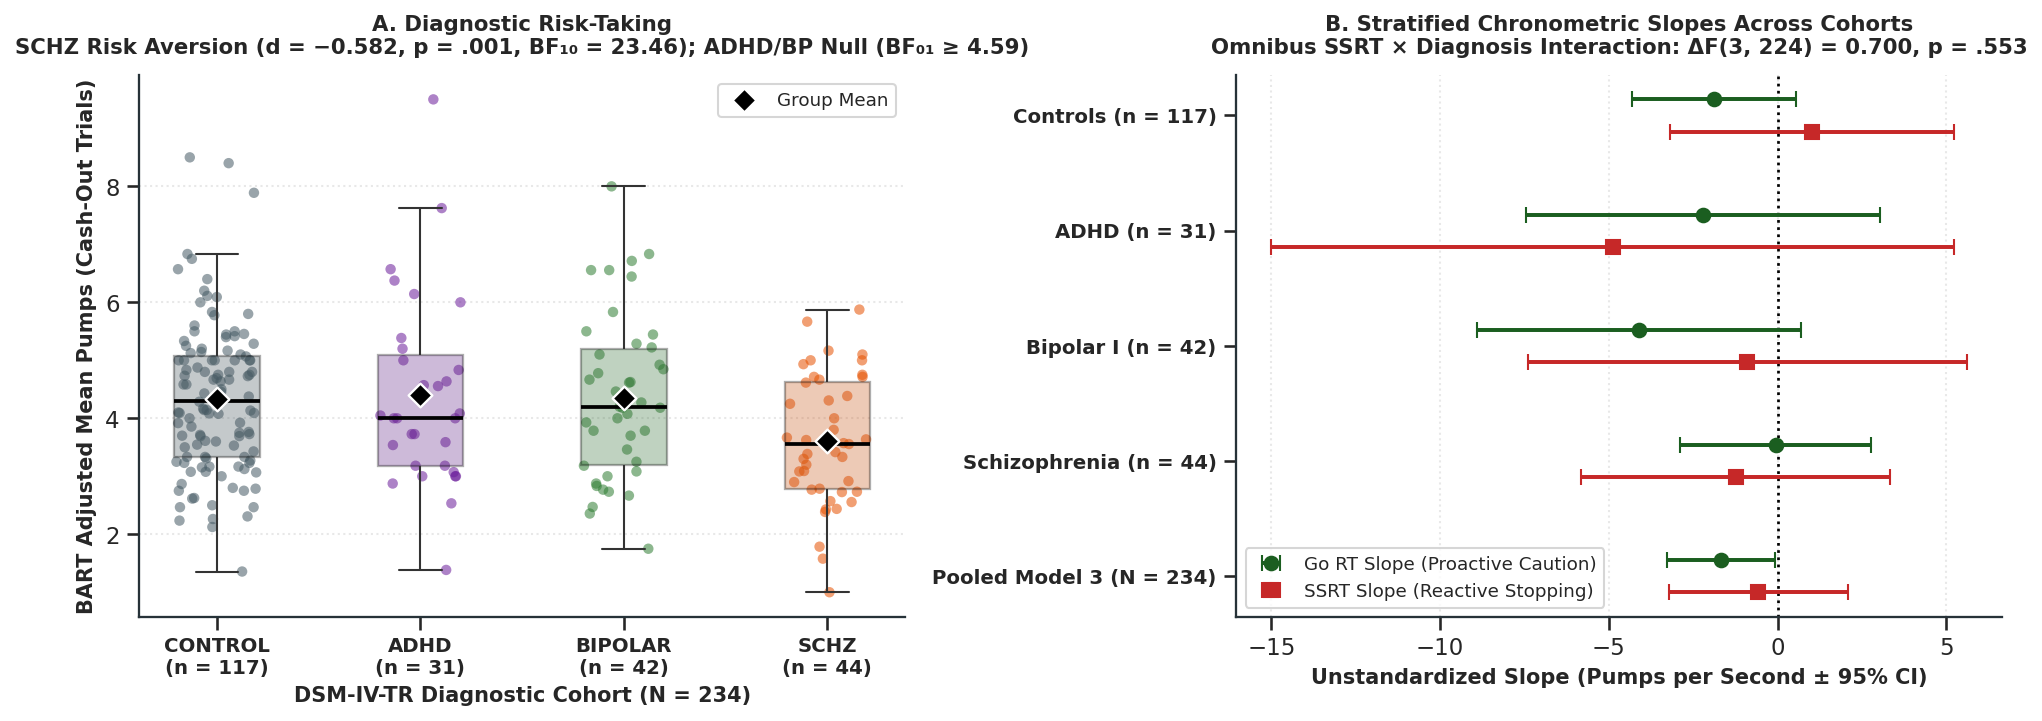

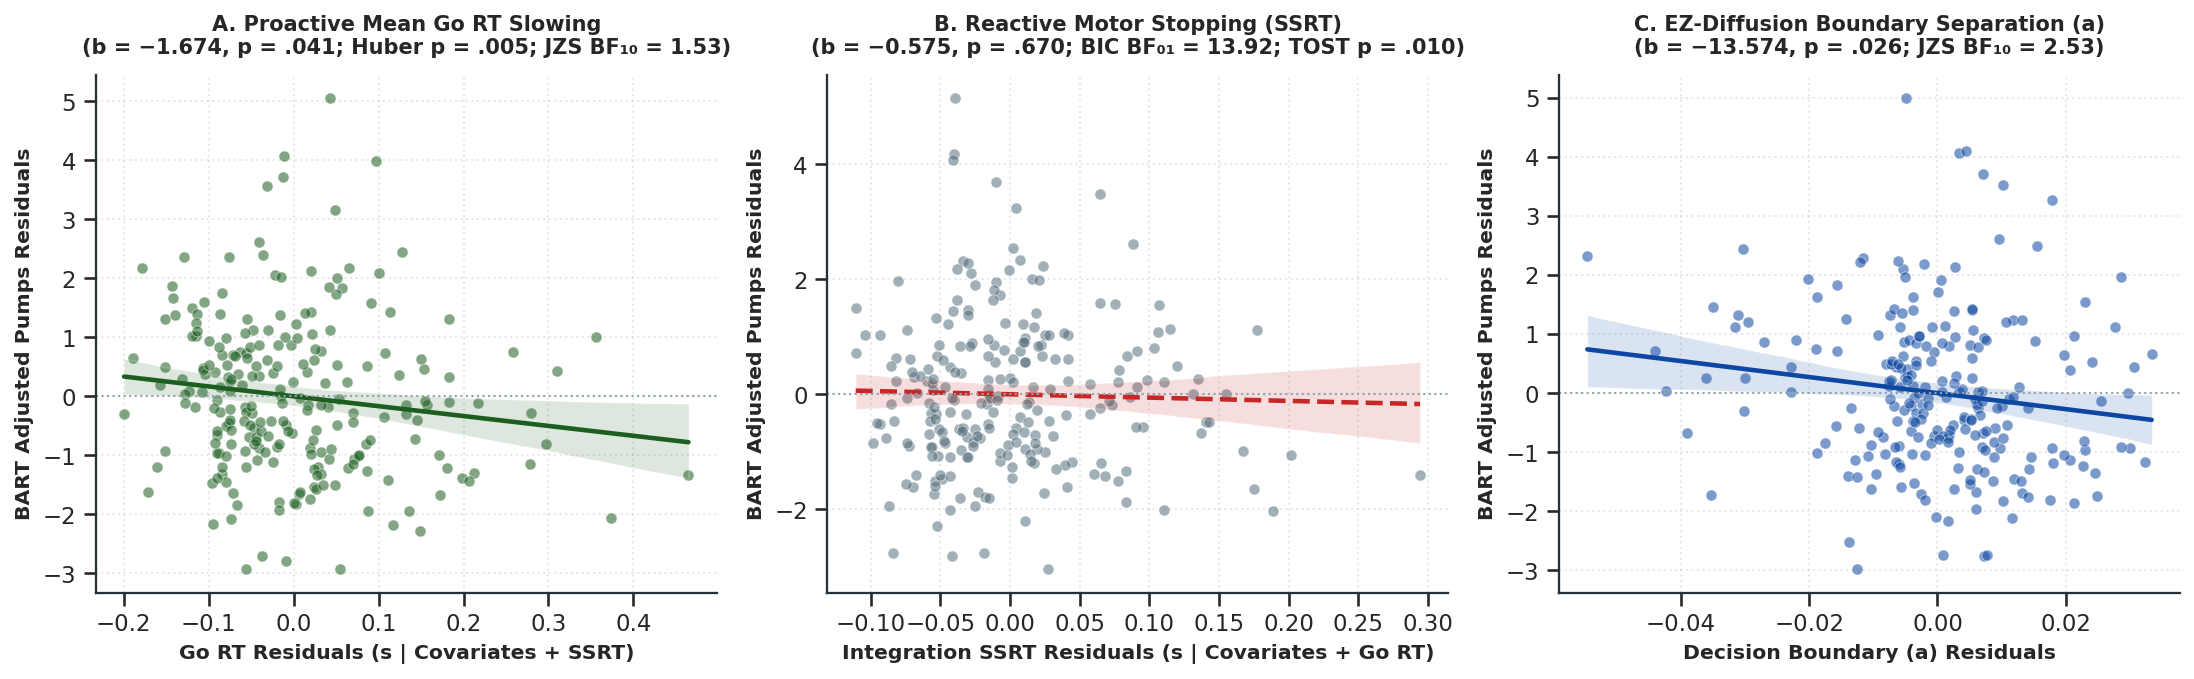

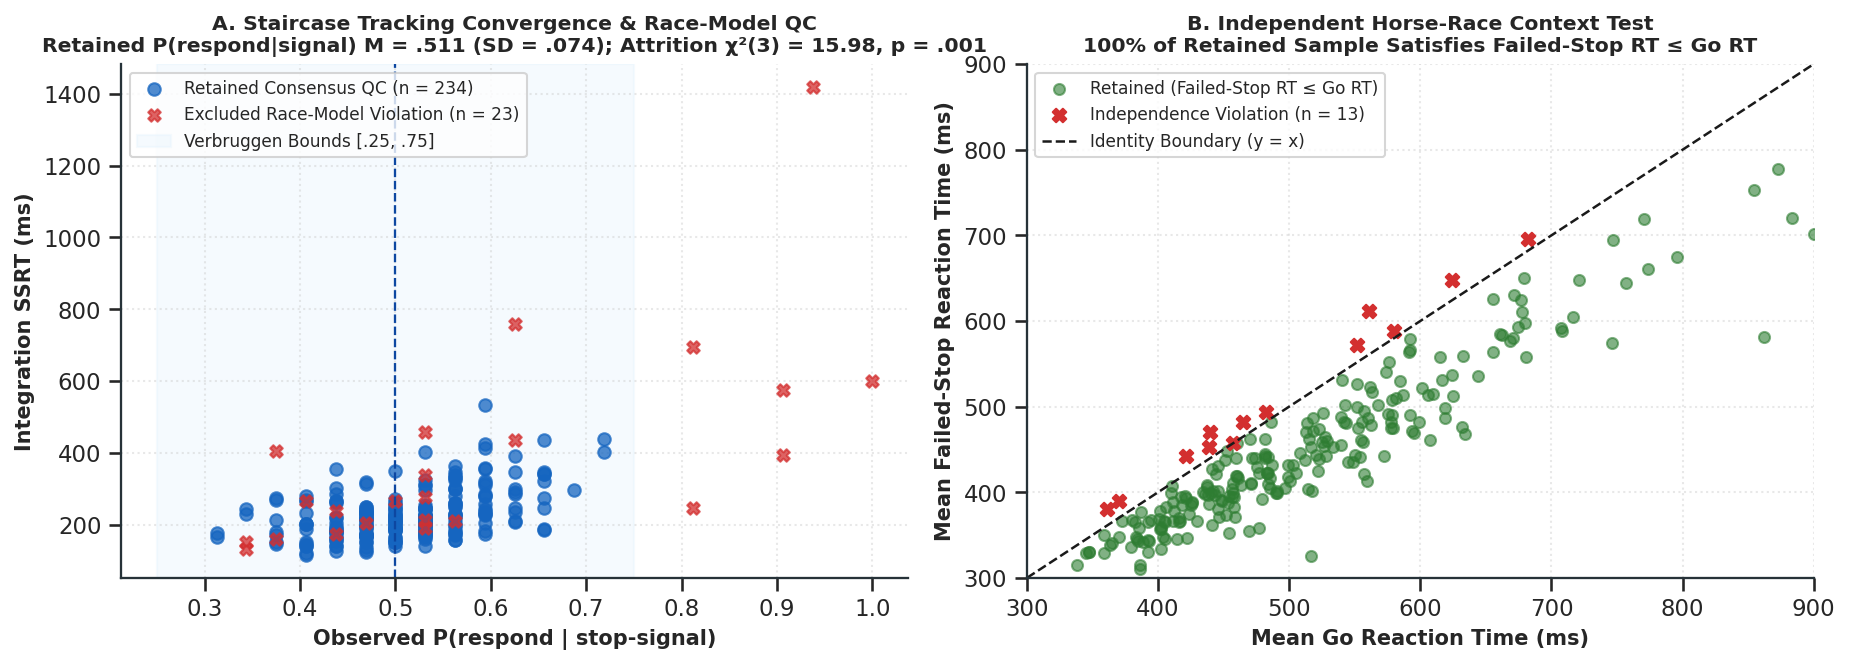

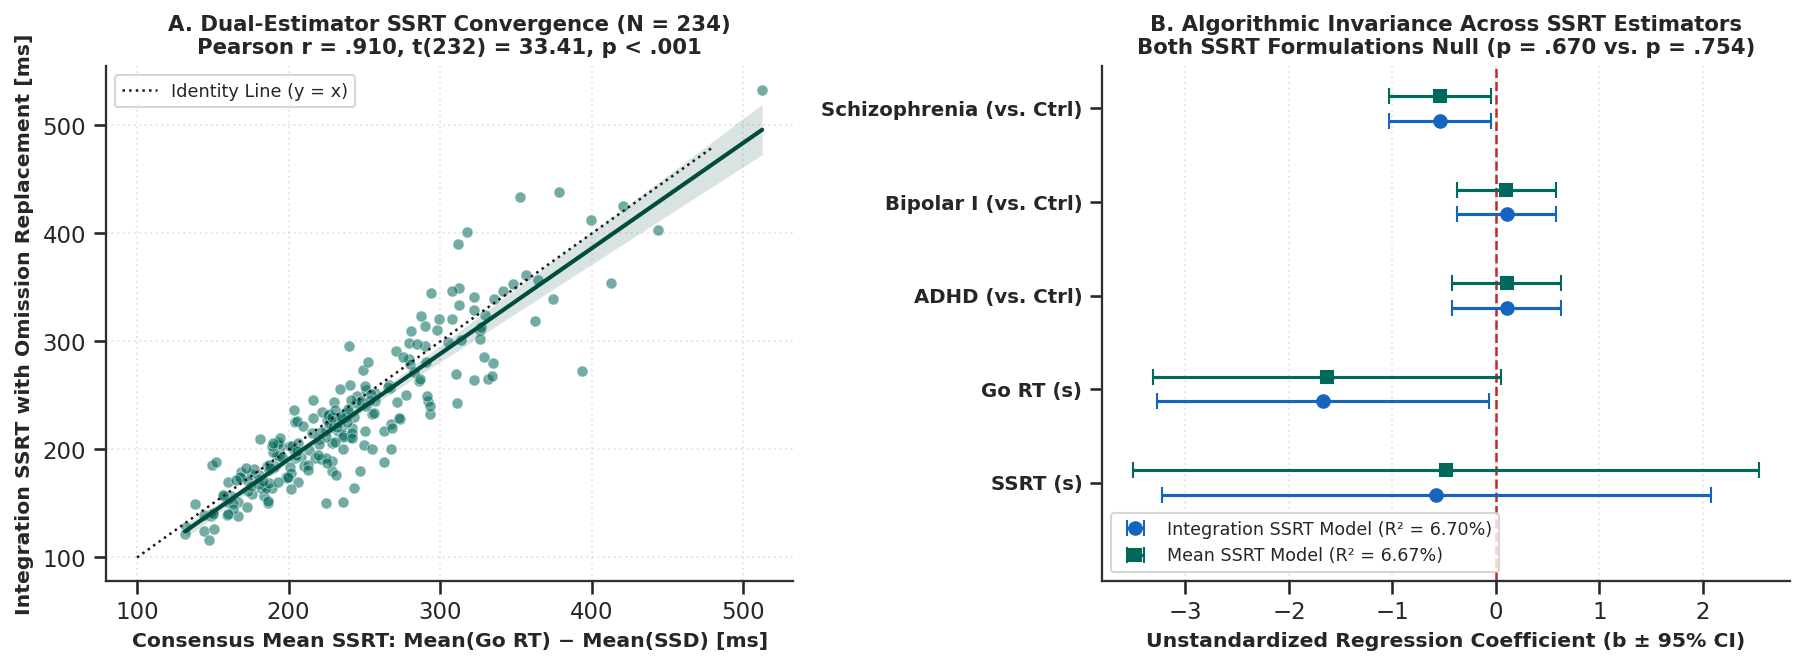

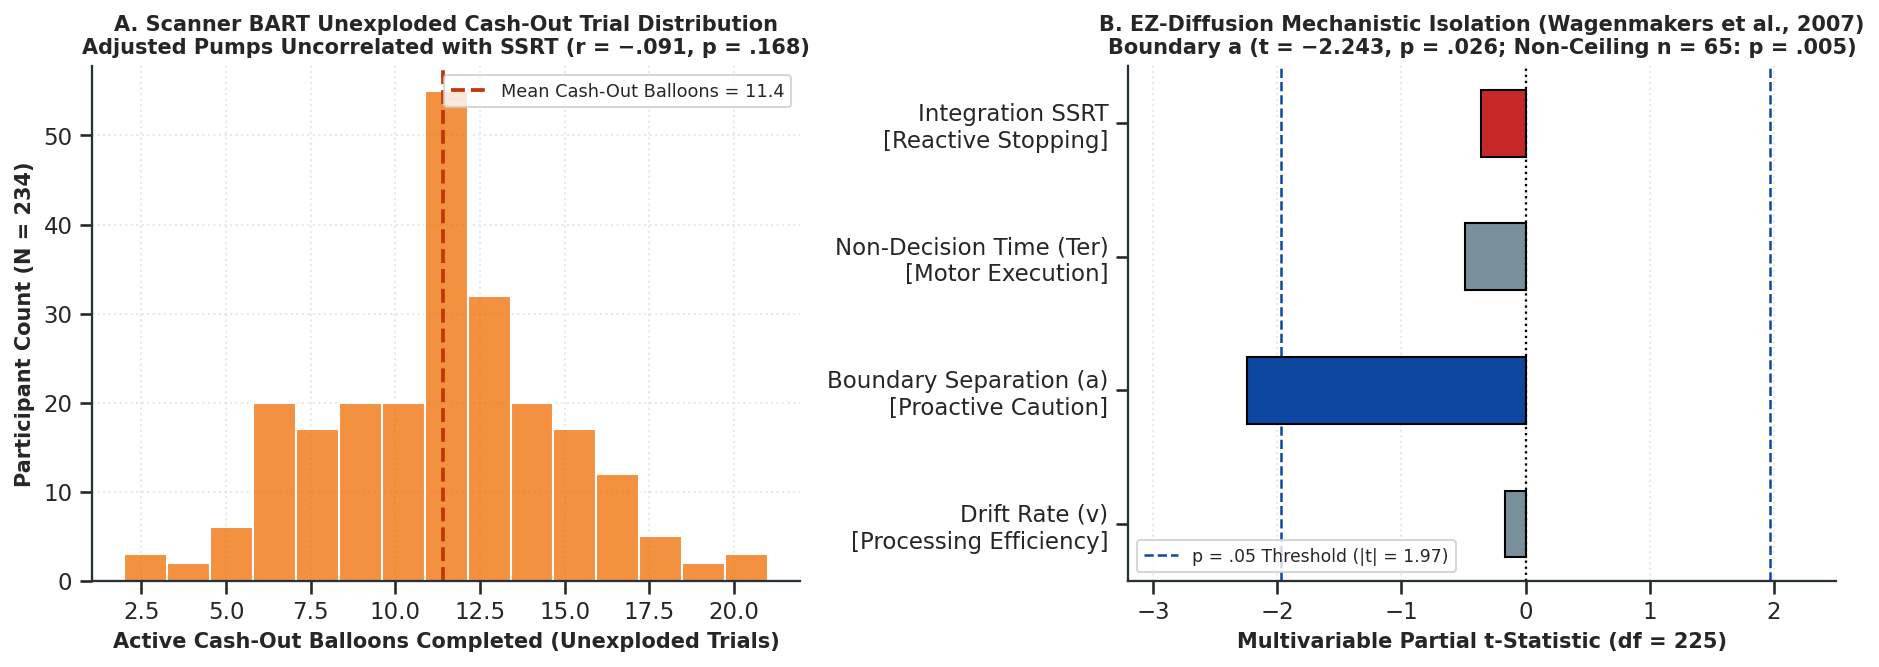

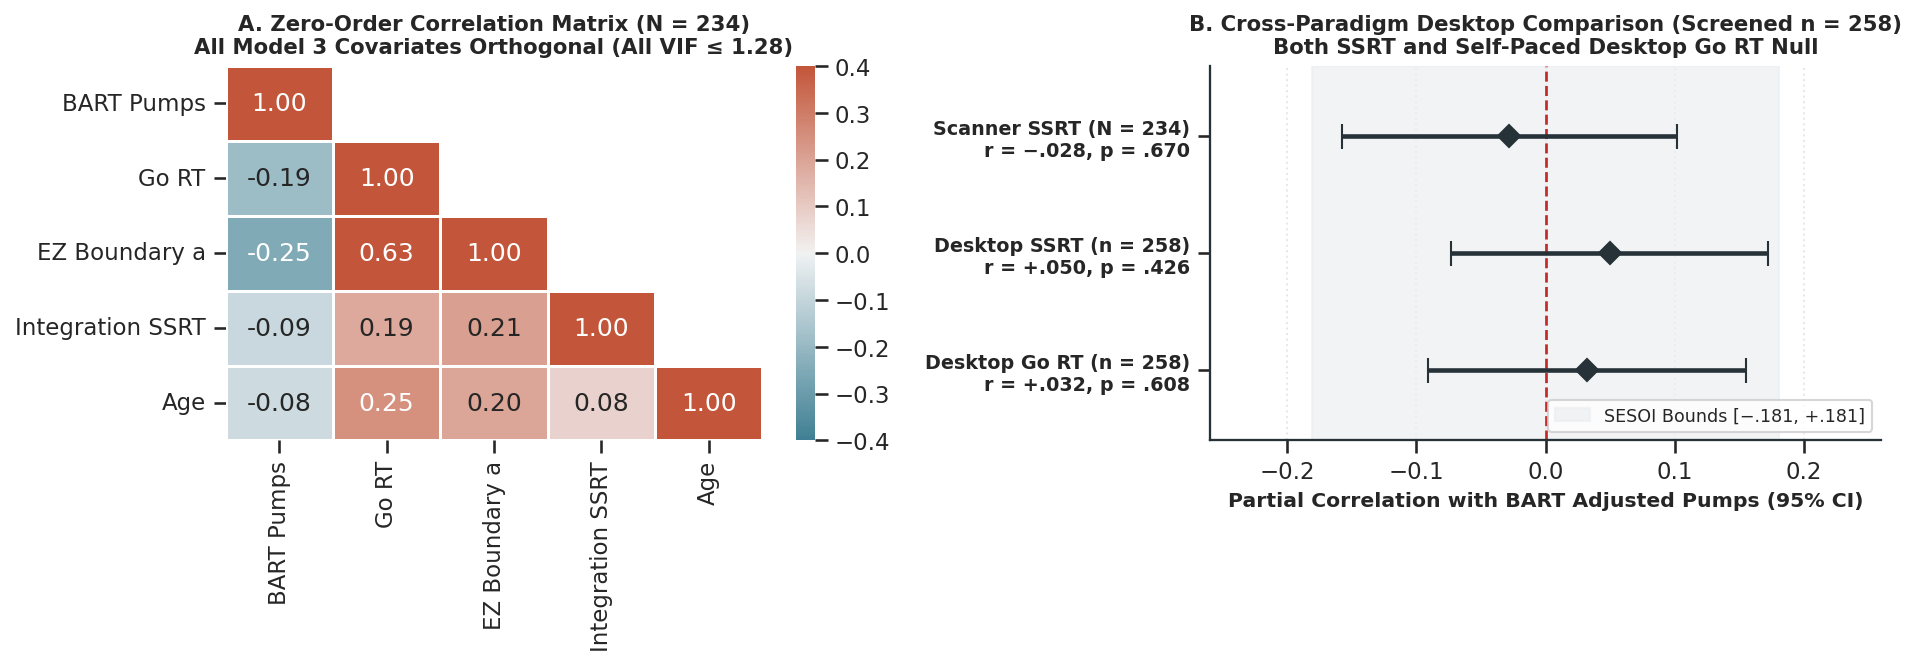

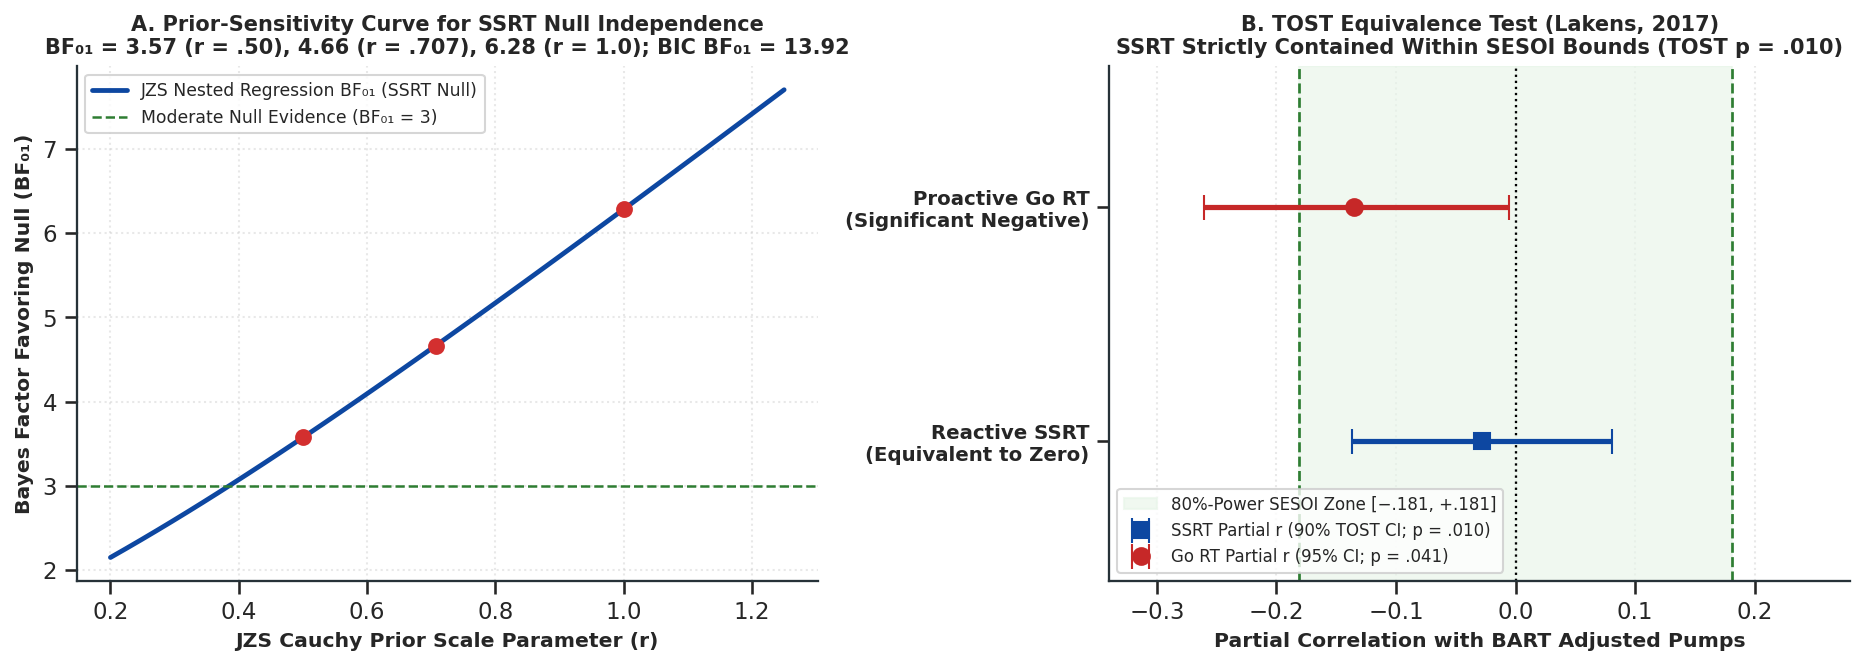

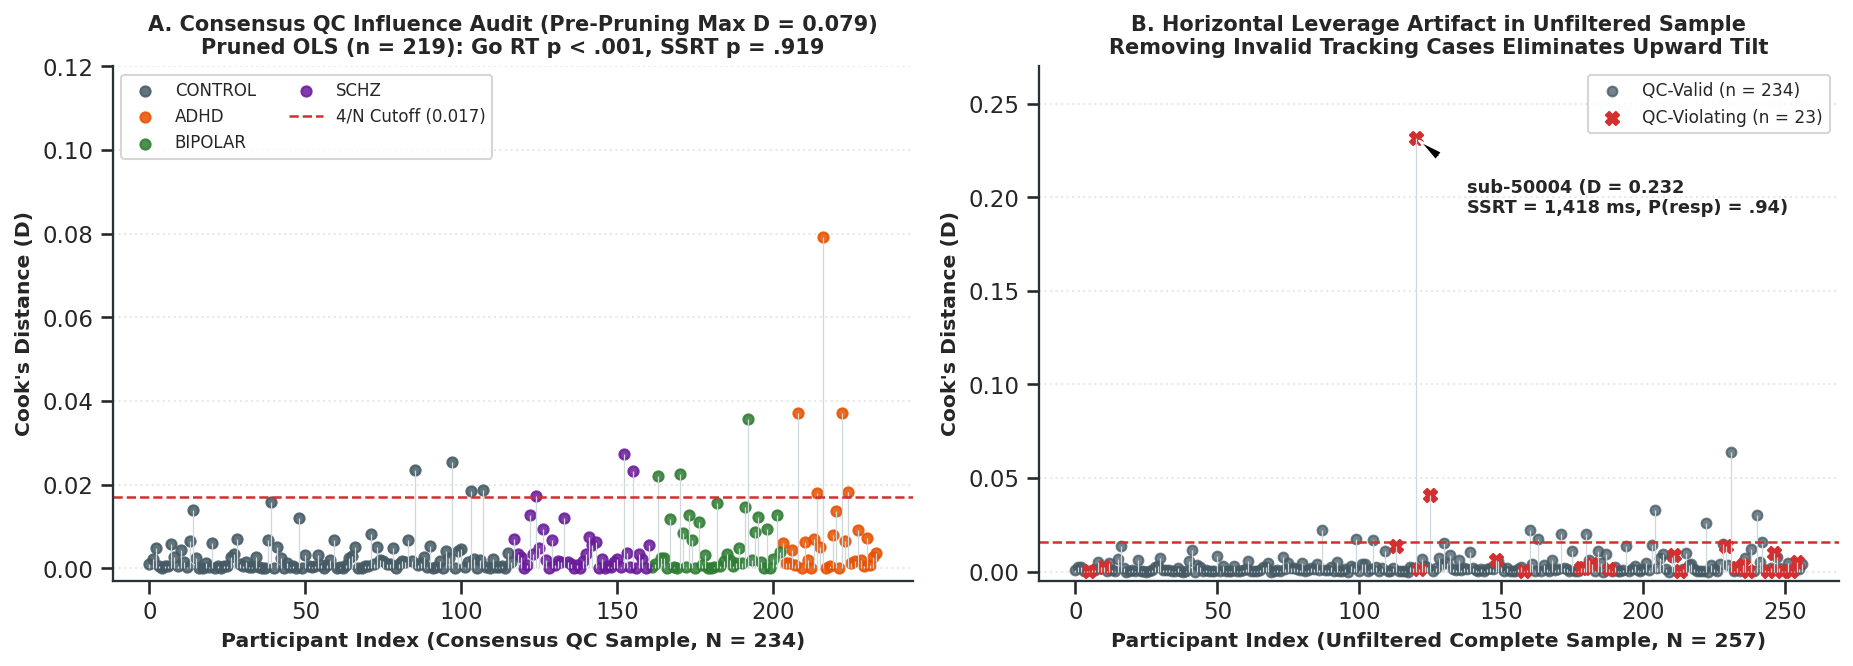

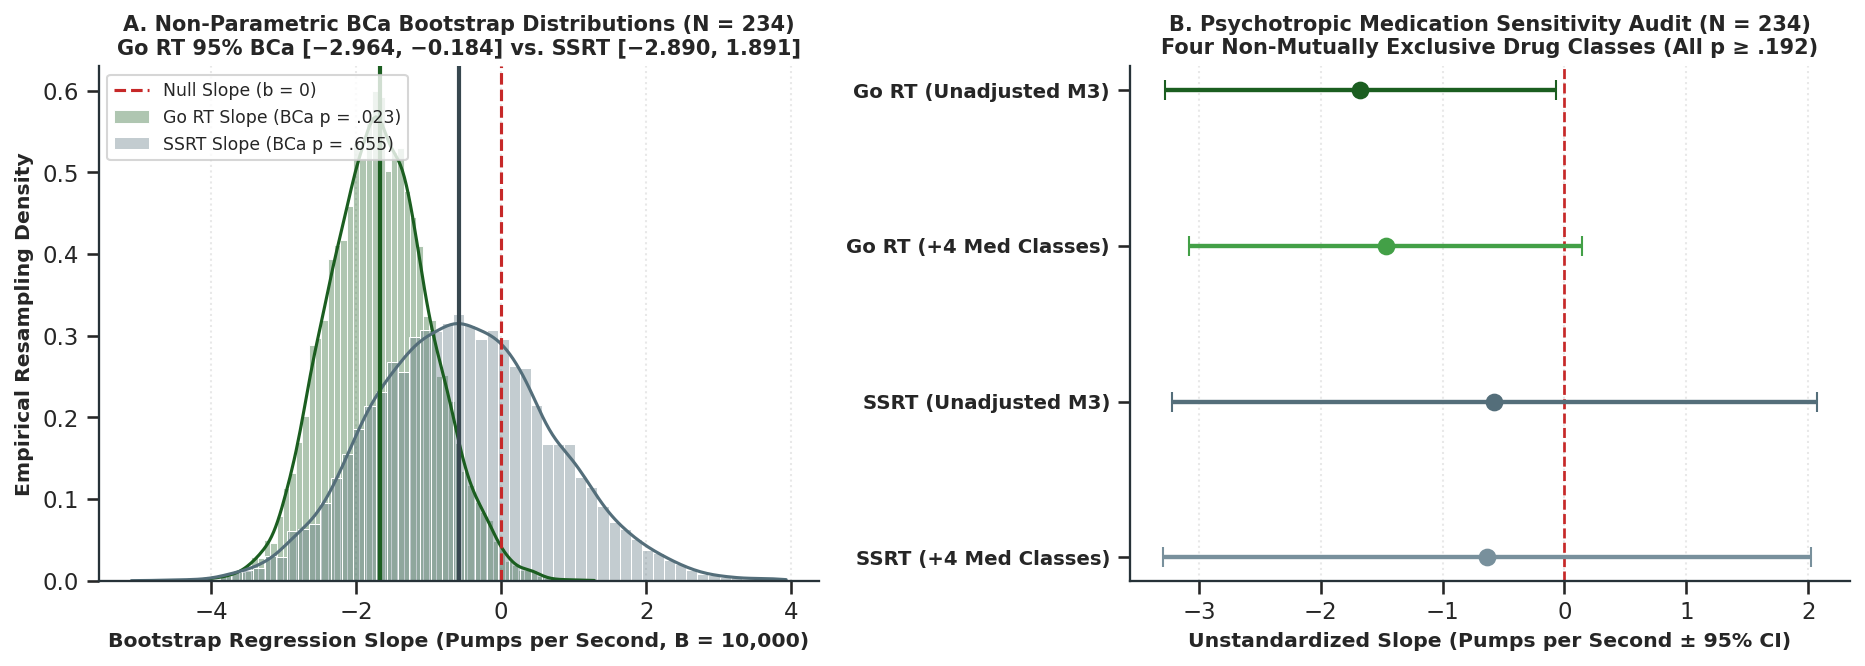

In [ ]:
FIG_DIR = "./figures"
os.makedirs(FIG_DIR, exist_ok=True)
order = ["CONTROL", "ADHD", "BIPOLAR", "SCHZ"]
pal = ["#455a64", "#e65100", "#2e7d32", "#6a1b9a"]
cnts = df["diagnosis"].value_counts()

X3 = np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"], df["ssrt_int_s"]])
b3 = np.linalg.lstsq(X3, y, rcond=None)[0]
s2_3 = np.sum((y - X3 @ b3) ** 2) / (N - 7)
se3 = np.sqrt(np.diag(s2_3 * np.linalg.inv(X3.T @ X3)))
tc3 = stats.t.ppf(0.975, df=N - 7)

def resid_against(target, Z):
    return target - Z @ np.linalg.lstsq(Z, target, rcond=None)[0]
fig1, (ax1a, ax1b) = plt.subplots(1, 2, figsize=(13.2, 5.0), dpi=300)
xlabels = [f"{c}\n(n = {cnts[c]})" for c in order]

sns.stripplot(data=df, x="diagnosis", y="BART_adj_pumps", order=order, hue="diagnosis",
              palette=pal, legend=False, size=5, jitter=0.20, alpha=0.55, ax=ax1a, zorder=2)
sns.boxplot(data=df, x="diagnosis", y="BART_adj_pumps", order=order, hue="diagnosis",
            palette=pal, legend=False, width=0.42,
            boxprops=dict(alpha=0.32, edgecolor="black", linewidth=1.1),
            medianprops=dict(color="black", linewidth=1.8), fliersize=0, ax=ax1a, zorder=3)
means_d = df.groupby("diagnosis")["BART_adj_pumps"].mean().reindex(order)
ax1a.scatter(range(4), means_d, color="black", s=65, marker="D", edgecolor="white", linewidth=1.1, zorder=5, label="Group Mean")
ax1a.set_xticks(range(4))
ax1a.set_xticklabels(xlabels, fontsize=9.5, fontweight="bold")
ax1a.set_ylabel("BART Adjusted Mean Pumps (Cash-Out Trials)", fontsize=10, fontweight="bold")
ax1a.set_xlabel("DSM-IV-TR Diagnostic Cohort (N = 234)", fontsize=10, fontweight="bold")
ax1a.set_title("A. Diagnostic Risk-Taking\nSCHZ Risk Aversion (d = −0.582, p = .001, BF₁₀ = 23.46); ADHD/BP Null (BF₀₁ ≥ 4.59)", fontsize=10.2, fontweight="bold", pad=10)
ax1a.legend(loc="upper right", frameon=True, facecolor="white", fontsize=8.8)
ax1a.grid(axis="y", linestyle=":", alpha=0.45)
sns.despine(ax=ax1a, top=True, right=True)

y_positions = np.arange(5)
cohort_labels = [f"Controls (n = {cnts['CONTROL']})", f"ADHD (n = {cnts['ADHD']})", f"Bipolar I (n = {cnts['BIPOLAR']})", f"Schizophrenia (n = {cnts['SCHZ']})", f"Pooled Model 3 (N = {N})"]
g_betas, g_los, g_his = [], [], []
s_betas, s_los, s_his = [], [], []
for g in order:
    mg = df["diagnosis"] == g
    Xg = np.column_stack([np.ones(mg.sum()), df.loc[mg, "age"], df.loc[mg, "go_rt_s"], df.loc[mg, "ssrt_int_s"]])
    yg = y[mg]
    bg = np.linalg.lstsq(Xg, yg, rcond=None)[0]
    s2g = np.sum((yg - Xg @ bg)**2) / (len(yg) - 4)
    seg = np.sqrt(np.diag(s2g * np.linalg.inv(Xg.T @ Xg)))
    tc = stats.t.ppf(0.975, df=len(yg)-4)
    g_betas.append(bg[2]); g_los.append(bg[2]-tc*seg[2]); g_his.append(bg[2]+tc*seg[2])
    s_betas.append(bg[3]); s_los.append(bg[3]-tc*seg[3]); s_his.append(bg[3]+tc*seg[3])

g_betas.append(b3[5]); g_los.append(b3[5]-tc3*se3[5]); g_his.append(b3[5]+tc3*se3[5])
s_betas.append(b3[6]); s_los.append(b3[6]-tc3*se3[6]); s_his.append(b3[6]+tc3*se3[6])

ax1b.axvline(0, color="black", linestyle=":", linewidth=1.3)
off = 0.14
ax1b.errorbar(g_betas, y_positions - off, xerr=[np.array(g_betas)-np.array(g_los), np.array(g_his)-np.array(g_betas)],
              fmt="o", color="#1b5e20", ecolor="#1b5e20", elinewidth=1.9, capsize=4, markersize=6.5, label="Go RT Slope (Proactive Caution)")
ax1b.errorbar(s_betas, y_positions + off, xerr=[np.array(s_betas)-np.array(s_los), np.array(s_his)-np.array(s_betas)],
              fmt="s", color="#c62828", ecolor="#c62828", elinewidth=1.9, capsize=4, markersize=6.5, label="SSRT Slope (Reactive Stopping)")
ax1b.set_yticks(y_positions)
ax1b.set_yticklabels(cohort_labels, fontsize=9.5, fontweight="bold")
ax1b.invert_yaxis()
ax1b.set_xlabel("Unstandardized Slope (Pumps per Second ± 95% CI)", fontsize=10, fontweight="bold")
ax1b.set_title("B. Stratified Chronometric Slopes Across Cohorts\nOmnibus SSRT × Diagnosis Interaction: ΔF(3, 224) = 0.700, p = .553", fontsize=10.2, fontweight="bold", pad=10)
ax1b.legend(loc="lower left", frameon=True, facecolor="white", fontsize=8.8)
ax1b.grid(axis="x", linestyle=":", alpha=0.45)
sns.despine(ax=ax1b, top=True, right=True)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/Figure1_Diagnostic_and_Stratified_Slopes.png", dpi=300, bbox_inches="tight")
plt.show()

Z_base = np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"]])
Z_for_gort = np.column_stack([Z_base, df["ssrt_int_s"]])
Z_for_ssrt = np.column_stack([Z_base, df["go_rt_s"]])
Z_for_eza = np.column_stack([Z_base, df["EZ_v"], df["EZ_Ter_ms"]/1000.0, df["ssrt_int_s"]])

rx_gort, ry_gort = resid_against(df["go_rt_s"].values, Z_for_gort), resid_against(y, Z_for_gort)
rx_ssrt, ry_ssrt = resid_against(df["ssrt_int_s"].values, Z_for_ssrt), resid_against(y, Z_for_ssrt)
rx_eza, ry_eza = resid_against(df["EZ_a"].values, Z_for_eza), resid_against(y, Z_for_eza)

fig2, axes = plt.subplots(1, 3, figsize=(14.8, 4.7), dpi=300)
sns.regplot(x=rx_gort, y=ry_gort, ax=axes[0], color="#1b5e20",
            scatter_kws={"alpha": 0.55, "s": 28, "edgecolor": "white", "linewidths": 0.4},
            line_kws={"color": "#1b5e20", "linewidth": 2.2})
axes[0].axhline(0, color="#90a4ae", linestyle=":", linewidth=1.0)
axes[0].set_title("A. Proactive Mean Go RT Slowing\n(b = −1.674, p = .041; Huber p = .005; JZS BF₁₀ = 1.53)", fontsize=10.0, fontweight="bold", pad=10)
axes[0].set_xlabel("Go RT Residuals (s | Covariates + SSRT)", fontsize=9.8, fontweight="bold")
axes[0].set_ylabel("BART Adjusted Pumps Residuals", fontsize=9.8, fontweight="bold")
axes[0].grid(True, linestyle=":", alpha=0.45)

sns.regplot(x=rx_ssrt, y=ry_ssrt, ax=axes[1], color="#546e7a",
            scatter_kws={"alpha": 0.55, "s": 28, "edgecolor": "white", "linewidths": 0.4},
            line_kws={"color": "#c62828", "linewidth": 2.2, "linestyle": "--"})
axes[1].axhline(0, color="#90a4ae", linestyle=":", linewidth=1.0)
axes[1].set_title("B. Reactive Motor Stopping (SSRT)\n(b = −0.575, p = .670; BIC BF₀₁ = 13.92; TOST p = .010)", fontsize=10.0, fontweight="bold", pad=10)
axes[1].set_xlabel("Integration SSRT Residuals (s | Covariates + Go RT)", fontsize=9.8, fontweight="bold")
axes[1].set_ylabel("BART Adjusted Pumps Residuals", fontsize=9.8, fontweight="bold")
axes[1].grid(True, linestyle=":", alpha=0.45)

sns.regplot(x=rx_eza, y=ry_eza, ax=axes[2], color="#0d47a1",
            scatter_kws={"alpha": 0.55, "s": 28, "edgecolor": "white", "linewidths": 0.4},
            line_kws={"color": "#0d47a1", "linewidth": 2.2})
axes[2].axhline(0, color="#90a4ae", linestyle=":", linewidth=1.0)
axes[2].set_title("C. EZ-Diffusion Boundary Separation (a)\n(b = −13.574, p = .026; JZS BF₁₀ = 2.53)", fontsize=10.0, fontweight="bold", pad=10)
axes[2].set_xlabel("Decision Boundary (a) Residuals", fontsize=9.8, fontweight="bold")
axes[2].set_ylabel("BART Adjusted Pumps Residuals", fontsize=9.8, fontweight="bold")
axes[2].grid(True, linestyle=":", alpha=0.45)

for ax in axes:
    sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/Figure2_Proactive_vs_Reactive_Dissociation.png", dpi=300, bbox_inches="tight")
plt.show()

figS1, (axs1a, axs1b) = plt.subplots(1, 2, figsize=(12.5, 4.6), dpi=220)
qc_status = np.where(qc_mask, "Retained Consensus QC (n = 234)", "Excluded Race-Model Violation (n = 23)")
for lbl, col, mk in [("Retained Consensus QC (n = 234)", "#1565c0", "o"), ("Excluded Race-Model Violation (n = 23)", "#d32f2f", "X")]:
    m_k = qc_status == lbl
    axs1a.scatter(df257.loc[m_k, "P_respond_signal"], df257.loc[m_k, "SSRT_ms"], c=col, marker=mk, s=36, alpha=0.75, label=lbl)
axs1a.axvspan(0.25, 0.75, color="#e3f2fd", alpha=0.35, zorder=0, label="Verbruggen Bounds [.25, .75]")
axs1a.axvline(0.50, color="#0d47a1", linestyle="--", linewidth=1.1)
axs1a.set_xlabel("Observed P(respond | stop-signal)", fontsize=10, fontweight="bold")
axs1a.set_ylabel("Integration SSRT (ms)", fontsize=10, fontweight="bold")
axs1a.set_title("A. Staircase Tracking Convergence & Race-Model QC\nRetained P(respond|signal) M = .511 (SD = .074); Attrition χ²(3) = 15.98, p = .001", fontsize=9.8, fontweight="bold")
axs1a.legend(loc="upper left", frameon=True, facecolor="white", fontsize=8.2)
axs1a.grid(True, linestyle=":", alpha=0.45)

axs1b.scatter(df["Mean_Go_RT_ms"], df["Mean_Failed_Stop_RT_ms"], color="#2e7d32", alpha=0.6, s=28, label="Retained (Failed-Stop RT ≤ Go RT)")
viol_ind = df257["Violates_Independence"] == 1
axs1b.scatter(df257.loc[viol_ind, "Mean_Go_RT_ms"], df257.loc[viol_ind, "Mean_Failed_Stop_RT_ms"], color="#d32f2f", marker="X", s=42, label="Independence Violation (n = 13)")
lims = [300, 900]
axs1b.plot(lims, lims, "k--", linewidth=1.2, label="Identity Boundary (y = x)")
axs1b.set_xlim(lims); axs1b.set_ylim(lims)
axs1b.set_xlabel("Mean Go Reaction Time (ms)", fontsize=10, fontweight="bold")
axs1b.set_ylabel("Mean Failed-Stop Reaction Time (ms)", fontsize=10, fontweight="bold")
axs1b.set_title("B. Independent Horse-Race Context Test\n100% of Retained Sample Satisfies Failed-Stop RT ≤ Go RT", fontsize=9.8, fontweight="bold")
axs1b.legend(loc="upper left", frameon=True, facecolor="white", fontsize=8.2)
axs1b.grid(True, linestyle=":", alpha=0.45)
for ax in (axs1a, axs1b): sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/FigureS1_Staircase_and_RaceModel_QC.png", dpi=220, bbox_inches="tight")
plt.show()

figS2, (axs2a, axs2b) = plt.subplots(1, 2, figsize=(12.2, 4.6), dpi=220)
sns.regplot(x=df["ssrt_mean_ms"], y=df["SSRT_ms"], ax=axs2a, color="#00695c",
            scatter_kws={"alpha": 0.55, "s": 28, "edgecolor": "white", "linewidths": 0.4},
            line_kws={"color": "#004d40", "linewidth": 2.0})
axs2a.plot([100, 480], [100, 480], "k:", linewidth=1.2, label="Identity Line (y = x)")
axs2a.set_xlabel("Consensus Mean SSRT: Mean(Go RT) − Mean(SSD) [ms]", fontsize=9.8, fontweight="bold")
axs2a.set_ylabel("Integration SSRT with Omission Replacement [ms]", fontsize=9.8, fontweight="bold")
axs2a.set_title("A. Dual-Estimator SSRT Convergence (N = 234)\nPearson r = .910, t(232) = 33.41, p < .001", fontsize=10.2, fontweight="bold")
axs2a.legend(loc="upper left", frameon=True, facecolor="white", fontsize=8.5)
axs2a.grid(True, linestyle=":", alpha=0.45)

X_log = np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"], df["ssrt_mean_s"]])
b_log = np.linalg.lstsq(X_log, y, rcond=None)[0]
se_log = np.sqrt(np.diag((np.sum((y - X_log @ b_log)**2)/(N-7)) * np.linalg.inv(X_log.T @ X_log)))
tc = stats.t.ppf(0.975, df=N-7)
f_lbls = ["SSRT (s)", "Go RT (s)", "ADHD (vs. Ctrl)", "Bipolar I (vs. Ctrl)", "Schizophrenia (vs. Ctrl)"]
idx_ord = [6, 5, 1, 2, 3]
yp = np.arange(len(f_lbls))
axs2b.axvline(0, color="#c62828", linestyle="--", linewidth=1.2)
axs2b.errorbar([b3[i] for i in idx_ord], yp - 0.13, xerr=[tc*se3[i] for i in idx_ord], fmt="o", color="#1565c0", capsize=4, label="Integration SSRT Model (R² = 6.70%)")
axs2b.errorbar([b_log[i] for i in idx_ord], yp + 0.13, xerr=[tc*se_log[i] for i in idx_ord], fmt="s", color="#00695c", capsize=4, label="Mean SSRT Model (R² = 6.67%)")
axs2b.set_yticks(yp); axs2b.set_yticklabels(f_lbls, fontsize=9.5, fontweight="bold")
axs2b.set_ylim(-1.05, 4.45)
axs2b.set_xlabel("Unstandardized Regression Coefficient (b ± 95% CI)", fontsize=9.8, fontweight="bold")
axs2b.set_title("B. Algorithmic Invariance Across SSRT Estimators\nBoth SSRT Formulations Null (p = .670 vs. p = .754)", fontsize=10.2, fontweight="bold")
axs2b.legend(loc="lower left", frameon=True, facecolor="white", fontsize=8.4)
axs2b.grid(axis="x", linestyle=":", alpha=0.45)
for ax in (axs2a, axs2b): sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/FigureS2_SSRT_Construct_Convergence.png", dpi=220, bbox_inches="tight")
plt.show()

figS3, (axs3a, axs3b) = plt.subplots(1, 2, figsize=(12.5, 4.6), dpi=220)
sns.histplot(df["BART_cashout_balloons"], bins=15, color="#ef6c00", edgecolor="white", alpha=0.75, ax=axs3a)
axs3a.axvline(df["BART_cashout_balloons"].mean(), color="#bf360c", linestyle="--", linewidth=1.8,
              label=f"Mean Cash-Out Balloons = {df['BART_cashout_balloons'].mean():.1f}")
axs3a.set_xlabel("Active Cash-Out Balloons Completed (Unexploded Trials)", fontsize=10, fontweight="bold")
axs3a.set_ylabel("Participant Count (N = 234)", fontsize=10, fontweight="bold")
axs3a.set_title("A. Scanner BART Unexploded Cash-Out Trial Distribution\nAdjusted Pumps Uncorrelated with SSRT (r = −.091, p = .168)", fontsize=10.0, fontweight="bold")
axs3a.legend(loc="upper right", frameon=True, facecolor="white", fontsize=8.5)
axs3a.grid(True, linestyle=":", alpha=0.45)

X_ez = np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["EZ_v"], df["EZ_a"], df["EZ_Ter_ms"]/1000.0, df["ssrt_int_s"]])
b_ez = np.linalg.lstsq(X_ez, y, rcond=None)[0]
s2_ez = np.sum((y - X_ez @ b_ez)**2) / (N - 9)
se_ez = np.sqrt(np.diag(s2_ez * np.linalg.inv(X_ez.T @ X_ez)))
t_ez = b_ez[5:] / se_ez[5:]
ez_names = ["Drift Rate (v)\n[Processing Efficiency]", "Boundary Separation (a)\n[Proactive Caution]", "Non-Decision Time (Ter)\n[Motor Execution]", "Integration SSRT\n[Reactive Stopping]"]
cols_ez = ["#78909c", "#0d47a1", "#78909c", "#c62828"]
axs3b.barh(ez_names, t_ez, color=cols_ez, edgecolor="black", height=0.50)
axs3b.axvline(-stats.t.ppf(0.975, df=N-9), color="#0d47a1", linestyle="--", linewidth=1.2, label="p = .05 Threshold (|t| = 1.97)")
axs3b.axvline(stats.t.ppf(0.975, df=N-9), color="#0d47a1", linestyle="--", linewidth=1.2)
axs3b.axvline(0, color="black", linestyle=":", linewidth=1.1)
axs3b.set_xlim(-3.2, 2.5)
axs3b.set_xlabel("Multivariable Partial t-Statistic (df = 225)", fontsize=10, fontweight="bold")
axs3b.set_title("B. EZ-Diffusion Mechanistic Isolation (Wagenmakers et al., 2007)\nBoundary a (t = −2.243, p = .026; Non-Ceiling n = 65: p = .005)", fontsize=10.0, fontweight="bold")
axs3b.legend(loc="lower left", frameon=True, facecolor="white", fontsize=8.3)
axs3b.grid(axis="x", linestyle=":", alpha=0.45)
for ax in (axs3a, axs3b): sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/FigureS3_BART_Cashouts_and_EZ_Diffusion.png", dpi=220, bbox_inches="tight")
plt.show()

t_g = b3[5] / se3[5]
t_s = b3[6] / se3[6]
rp_g = t_g / np.sqrt(t_g**2 + (N - 7))
rp_s = t_s / np.sqrt(t_s**2 + (N - 7))
sez = 1.0 / np.sqrt((N - 7) - 1)
ci95_s = np.tanh([np.arctanh(rp_s) - 1.96*sez, np.arctanh(rp_s) + 1.96*sez])

figS4, (axs4a, axs4b) = plt.subplots(1, 2, figsize=(12.8, 4.6), dpi=220)
c_vars = ["BART_adj_pumps", "go_rt_s", "EZ_a", "ssrt_int_s", "age"]
c_lbls = ["BART Pumps", "Go RT", "EZ Boundary a", "Integration SSRT", "Age"]
corr_m = df[c_vars].corr()
mask_u = np.triu(np.ones_like(corr_m, dtype=bool), k=1)
sns.heatmap(corr_m, mask=mask_u, annot=True, fmt=".2f", cmap=sns.diverging_palette(220, 20, as_cmap=True),
            vmin=-0.4, vmax=0.4, center=0, cbar=True, linewidths=1.2, linecolor="white",
            xticklabels=c_lbls, yticklabels=c_lbls, ax=axs4a)
axs4a.set_title("A. Zero-Order Correlation Matrix (N = 234)\nAll Model 3 Covariates Orthogonal (All VIF ≤ 1.28)", fontsize=10.2, fontweight="bold")

desk = df_all.dropna(subset=["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt", "age", "diagnosis"]).copy()
for c in ["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt", "sst_ses_percent_inhib", "sst_ses_percent_go_response"]:
    if c in desk.columns:
        desk[c] = pd.to_numeric(desk[c], errors="coerce")
desk = desk.dropna(subset=["bart_meanadjustedpumps", "sst_ses_ssrt", "sst_ses_median_rt"]).reset_index(drop=True)
desk_qc = desk[(desk["sst_ses_percent_inhib"] >= 0.25) & (desk["sst_ses_percent_inhib"] <= 0.75) & (desk["sst_ses_percent_go_response"] >= 0.85)].copy().reset_index(drop=True)
Nd = len(desk_qc)
Xd = np.column_stack([np.ones(Nd), (desk_qc["diagnosis"]=="ADHD").astype(float), (desk_qc["diagnosis"]=="BIPOLAR").astype(float), (desk_qc["diagnosis"]=="SCHZ").astype(float), desk_qc["age"].values, desk_qc["sst_ses_median_rt"].values/1000.0, desk_qc["sst_ses_ssrt"].values/1000.0])
yd = desk_qc["bart_meanadjustedpumps"].values
bd = np.linalg.lstsq(Xd, yd, rcond=None)[0]
sed = np.sqrt(np.diag((np.sum((yd - Xd @ bd)**2)/(Nd-7)) * np.linalg.inv(Xd.T @ Xd)))
td_g = bd[5] / sed[5]
td_s = bd[6] / sed[6]
rpd_g = td_g / np.sqrt(td_g**2 + (Nd - 7))
rpd_s = td_s / np.sqrt(td_s**2 + (Nd - 7))
sezd = 1.0 / np.sqrt((Nd - 7) - 1)
ci95_dg = np.tanh([np.arctanh(rpd_g) - 1.96*sezd, np.arctanh(rpd_g) + 1.96*sezd])
ci95_ds = np.tanh([np.arctanh(rpd_s) - 1.96*sezd, np.arctanh(rpd_s) + 1.96*sezd])

axs4b.axvline(0, color="#c62828", linestyle="--", linewidth=1.3)
axs4b.axvspan(-0.181, 0.181, color="#eceff1", alpha=0.7, label="SESOI Bounds [−.181, +.181]")
vals_d = [rp_s, rpd_s, rpd_g]
errs_lo = [rp_s - ci95_s[0], rpd_s - ci95_ds[0], rpd_g - ci95_dg[0]]
errs_hi = [ci95_s[1] - rp_s, ci95_ds[1] - rpd_s, ci95_dg[1] - rpd_g]
axs4b.errorbar(vals_d, [0, 1, 2], xerr=[errs_lo, errs_hi], fmt="D", color="#263238", ecolor="#263238", elinewidth=2.2, capsize=6, markersize=7.5)
axs4b.set_yticks([0, 1, 2])
axs4b.set_yticklabels([
    f"Scanner SSRT (N = {N})\nr = −.028, p = .670",
    f"Desktop SSRT (n = {Nd})\nr = +.050, p = .426",
    f"Desktop Go RT (n = {Nd})\nr = +.032, p = .608",
], fontsize=9.2, fontweight="bold")
axs4b.invert_yaxis()
axs4b.set_xlim(-0.26, 0.26); axs4b.set_ylim(2.6, -0.6)
axs4b.set_xlabel("Partial Correlation with BART Adjusted Pumps (95% CI)", fontsize=9.8, fontweight="bold")
axs4b.set_title("B. Cross-Paradigm Desktop Comparison (Screened n = 258)\nBoth SSRT and Self-Paced Desktop Go RT Null", fontsize=10.2, fontweight="bold")
axs4b.legend(loc="lower right", frameon=True, facecolor="white", fontsize=8.4)
axs4b.grid(axis="x", linestyle=":", alpha=0.45)
sns.despine(ax=axs4b, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/FigureS4_Correlation_VIF_and_Desktop_Replication.png", dpi=220, bbox_inches="tight")
plt.show()

r_grid = np.linspace(0.20, 1.25, 45)
X2 = np.column_stack([np.ones(N), df["ADHD"], df["BIPOLAR"], df["SCHZ"], df["age"], df["go_rt_s"]])
r2_2 = 1.0 - np.sum((y - X2 @ np.linalg.lstsq(X2, y, rcond=None)[0])**2) / np.sum((y - y.mean())**2)
r2_3 = 1.0 - np.sum((y - X3 @ b3)**2) / np.sum((y - y.mean())**2)

def nested_bf01(r_sc):
    def bf_vs_0(r2, k):
        def ig(u):
            lp = np.log(r_sc / np.sqrt(2*np.pi)) - 1.5*np.log(u) - (r_sc**2)/(2*u)
            lb = 0.5*(N - k - 1)*np.log(1 + N*u) - 0.5*(N - 1)*np.log(1 + N*u*(1 - r2))
            return np.exp(lp + lb)
        return integrate.quad(ig, 1e-10, np.inf, limit=250)[0]
    return bf_vs_0(r2_2, 5) / bf_vs_0(r2_3, 6)

bf01_curve = [nested_bf01(rv) for rv in r_grid]

figS5, (axs5a, axs5b) = plt.subplots(1, 2, figsize=(12.6, 4.6), dpi=220)
axs5a.plot(r_grid, bf01_curve, color="#0d47a1", linewidth=2.3, label="JZS Nested Regression BF₀₁ (SSRT Null)")
axs5a.axhline(3.0, color="#2e7d32", linestyle="--", linewidth=1.2, label="Moderate Null Evidence (BF₀₁ = 3)")
axs5a.scatter([0.50, 0.7071, 1.00], [nested_bf01(0.50), nested_bf01(0.7071), nested_bf01(1.00)], color="#d32f2f", s=50, zorder=5)
axs5a.set_xlabel("JZS Cauchy Prior Scale Parameter (r)", fontsize=9.8, fontweight="bold")
axs5a.set_ylabel("Bayes Factor Favoring Null (BF₀₁)", fontsize=9.8, fontweight="bold")
axs5a.set_title("A. Prior-Sensitivity Curve for SSRT Null Independence\nBF₀₁ = 3.57 (r = .50), 4.66 (r = .707), 6.28 (r = 1.0); BIC BF₀₁ = 13.92", fontsize=10.0, fontweight="bold")
axs5a.legend(loc="upper left", frameon=True, facecolor="white", fontsize=8.3)
axs5a.grid(True, linestyle=":", alpha=0.45)

ci90_s = np.tanh([np.arctanh(rp_s) - 1.64485*sez, np.arctanh(rp_s) + 1.64485*sez])
ci95_g = np.tanh([np.arctanh(rp_g) - 1.95996*sez, np.arctanh(rp_g) + 1.95996*sez])

axs5b.axvspan(-0.181, 0.181, color="#e8f5e9", alpha=0.65, label="80%-Power SESOI Zone [−.181, +.181]")
axs5b.axvline(-0.181, color="#2e7d32", linestyle="--", linewidth=1.3)
axs5b.axvline(0.181, color="#2e7d32", linestyle="--", linewidth=1.3)
axs5b.axvline(0, color="black", linestyle=":", linewidth=1.1)
axs5b.errorbar(rp_s, 0, xerr=[[rp_s - ci90_s[0]], [ci90_s[1] - rp_s]], fmt="s", color="#0d47a1", elinewidth=2.5, capsize=6, markersize=8, label="SSRT Partial r (90% TOST CI; p = .010)")
axs5b.errorbar(rp_g, 1, xerr=[[rp_g - ci95_g[0]], [ci95_g[1] - rp_g]], fmt="o", color="#c62828", elinewidth=2.5, capsize=6, markersize=8, label="Go RT Partial r (95% CI; p = .041)")
axs5b.set_yticks([0, 1]); axs5b.set_yticklabels(["Reactive SSRT\n(Equivalent to Zero)", "Proactive Go RT\n(Significant Negative)"], fontsize=9.5, fontweight="bold")
axs5b.set_xlim(-0.34, 0.28); axs5b.set_ylim(-0.6, 1.6)
axs5b.set_xlabel("Partial Correlation with BART Adjusted Pumps", fontsize=9.8, fontweight="bold")
axs5b.set_title("B. TOST Equivalence Test (Lakens, 2017)\nSSRT Strictly Contained Within SESOI Bounds (TOST p = .010)", fontsize=10.0, fontweight="bold")
axs5b.legend(loc="lower left", frameon=True, facecolor="white", fontsize=8.0)
axs5b.grid(axis="x", linestyle=":", alpha=0.45)
for ax in (axs5a, axs5b): sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/FigureS5_Bayesian_and_TOST_Equivalence.png", dpi=220, bbox_inches="tight")
plt.show()

figS6, (axs6a, axs6b) = plt.subplots(1, 2, figsize=(12.6, 4.6), dpi=220)
H3 = np.einsum("ij,jk,ik->i", X3, np.linalg.inv(X3.T @ X3), X3)
res3 = y - X3 @ b3
cd234 = (res3**2 / (7 * s2_3)) * (H3 / ((1 - H3)**2))
cut234 = 4.0 / N
for g, col in zip(order, pal):
    mk = (df["diagnosis"] == g).values
    axs6a.scatter(np.where(mk)[0], cd234[mk], color=col, s=24, alpha=0.85, label=g)
axs6a.vlines(range(N), 0, cd234, color="#cfd8dc", linewidth=0.6)
axs6a.axhline(cut234, color="#d32f2f", linestyle="--", linewidth=1.2, label=f"4/N Cutoff ({cut234:.3f})")
axs6a.set_ylim(-0.003, 0.12)
axs6a.set_xlabel("Participant Index (Consensus QC Sample, N = 234)", fontsize=9.8, fontweight="bold")
axs6a.set_ylabel("Cook's Distance (D)", fontsize=9.8, fontweight="bold")
axs6a.set_title("A. Consensus QC Influence Audit (Pre-Pruning Max D = 0.079)\nPruned OLS (n = 219): Go RT p < .001, SSRT p = .919", fontsize=10.0, fontweight="bold")
axs6a.legend(loc="upper left", ncol=2, frameon=True, facecolor="white", fontsize=8.0)
axs6a.grid(axis="y", linestyle=":", alpha=0.45)

X257 = np.column_stack([np.ones(len(df257)), df257["ADHD"], df257["BIPOLAR"], df257["SCHZ"], df257["age"], df257["go_rt_s"], df257["ssrt_int_s"]])
y257 = df257["BART_adj_pumps"].values
b257 = np.linalg.lstsq(X257, y257, rcond=None)[0]
s2_257 = np.sum((y257 - X257 @ b257)**2)/(len(df257)-7)
H257 = np.einsum("ij,jk,ik->i", X257, np.linalg.inv(X257.T @ X257), X257)
cd257 = ((y257 - X257 @ b257)**2 / (7 * s2_257)) * (H257 / ((1 - H257)**2))
axs6b.vlines(range(len(df257)), 0, cd257, color="#cfd8dc", linewidth=0.6)
axs6b.scatter(np.where(qc_mask)[0], cd257[qc_mask], color="#455a64", s=22, alpha=0.75, label="QC-Valid (n = 234)")
axs6b.scatter(np.where(~qc_mask)[0], cd257[~qc_mask], color="#d32f2f", marker="X", s=40, label="QC-Violating (n = 23)")
idx120 = int(np.argmax(cd257))
axs6b.annotate(f"sub-50004 (D = {cd257[idx120]:.3f}\nSSRT = 1,418 ms, P(resp) = .94)",
               xy=(idx120, cd257[idx120]), xytext=(idx120+18, cd257[idx120]-0.04),
               arrowprops=dict(facecolor="black", width=1, headwidth=5, shrink=0.06), fontsize=8.5, fontweight="bold")
axs6b.axhline(4.0/len(df257), color="#d32f2f", linestyle="--", linewidth=1.2)
axs6b.set_ylim(-0.005, 0.27)
axs6b.set_xlabel("Participant Index (Unfiltered Complete Sample, N = 257)", fontsize=9.8, fontweight="bold")
axs6b.set_ylabel("Cook's Distance (D)", fontsize=9.8, fontweight="bold")
axs6b.set_title("B. Horizontal Leverage Artifact in Unfiltered Sample\nRemoving Invalid Tracking Cases Eliminates Upward Tilt", fontsize=10.0, fontweight="bold")
axs6b.legend(loc="upper right", frameon=True, facecolor="white", fontsize=8.2)
axs6b.grid(axis="y", linestyle=":", alpha=0.45)
for ax in (axs6a, axs6b): sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/FigureS6_Cooks_Distance_Audit.png", dpi=220, bbox_inches="tight")
plt.show()

np.random.seed(42)
B = 10000
b_idx = np.random.choice(N, size=(B, N), replace=True)
bg, bs = np.empty(B), np.empty(B)
for i in range(B):
    cb = np.linalg.lstsq(X3[b_idx[i]], y[b_idx[i]], rcond=None)[0]
    bg[i], bs[i] = cb[5], cb[6]

figS7, (axs7a, axs7b) = plt.subplots(1, 2, figsize=(12.6, 4.6), dpi=220)
sns.histplot(bg, kde=True, stat="density", color="#1b5e20", alpha=0.35, label="Go RT Slope (BCa p = .023)", ax=axs7a)
sns.histplot(bs, kde=True, stat="density", color="#546e7a", alpha=0.35, label="SSRT Slope (BCa p = .655)", ax=axs7a)
axs7a.axvline(0, color="#c62828", linestyle="--", linewidth=1.5, label="Null Slope (b = 0)")
axs7a.axvline(b3[5], color="#1b5e20", linewidth=2.0)
axs7a.axvline(b3[6], color="#37474f", linewidth=2.0)
axs7a.set_xlabel("Bootstrap Regression Slope (Pumps per Second, B = 10,000)", fontsize=9.8, fontweight="bold")
axs7a.set_ylabel("Empirical Resampling Density", fontsize=9.8, fontweight="bold")
axs7a.set_title("A. Non-Parametric BCa Bootstrap Distributions (N = 234)\nGo RT 95% BCa [−2.964, −0.184] vs. SSRT [−2.890, 1.891]", fontsize=10.0, fontweight="bold")
axs7a.legend(loc="upper left", frameon=True, facecolor="white", fontsize=8.3)
axs7a.grid(axis="x", linestyle=":", alpha=0.45)

X_med = np.column_stack([X3, df["med_ap"], df["med_stim"], df["med_ms"], df["med_ad"]])
b_med = np.linalg.lstsq(X_med, y, rcond=None)[0]
se_med = np.sqrt(np.diag((np.sum((y - X_med @ b_med)**2)/(N-11)) * np.linalg.inv(X_med.T @ X_med)))
tc_m = stats.t.ppf(0.975, df=N-11)

m_labels = ["Go RT (Unadjusted M3)", "Go RT (+4 Med Classes)", "SSRT (Unadjusted M3)", "SSRT (+4 Med Classes)"]
m_vals = [b3[5], b_med[5], b3[6], b_med[6]]
m_errs = [tc3*se3[5], tc_m*se_med[5], tc3*se3[6], tc_m*se_med[6]]
m_cols = ["#1b5e20", "#43a047", "#546e7a", "#78909c"]
axs7b.axvline(0, color="#c62828", linestyle="--", linewidth=1.3)
for idx_p in range(4):
    axs7b.errorbar(m_vals[idx_p], idx_p, xerr=m_errs[idx_p], fmt="o", color=m_cols[idx_p], ecolor=m_cols[idx_p], elinewidth=2.1, capsize=5, markersize=7.5)
axs7b.set_yticks(range(4)); axs7b.set_yticklabels(m_labels, fontsize=9.5, fontweight="bold")
axs7b.invert_yaxis()
axs7b.set_xlabel("Unstandardized Slope (Pumps per Second ± 95% CI)", fontsize=9.8, fontweight="bold")
axs7b.set_title("B. Psychotropic Medication Sensitivity Audit (N = 234)\nFour Non-Mutually Exclusive Drug Classes (All p ≥ .192)", fontsize=10.0, fontweight="bold")
axs7b.grid(axis="x", linestyle=":", alpha=0.45)
for ax in (axs7a, axs7b): sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/FigureS7_Bootstrap_and_Medication.png", dpi=220, bbox_inches="tight")
plt.show()